# Table of Contents

**Phase 1: Data Preparation and First Reddit Map**
- **1.1 Preprocessing & Cleaning**
- **1.2 First Reddit Map**

**Phase 2: Defining Toxicity Metrics**
- **2.1 Toxicity score**
- **2.2 Toxicity binary classification**
- **2.3 Mapping the distribution of toxicity**

**Phase 3: Study of Propagation Types - Clustering & Injection in the Reddit Map**
- **3.1 Features Used for Clustering**
  - 3.1.1 Role-Aware Temporal Features: Source vs Target Behavior
  - 3.1.2 Network Features
- **3.2 Clustering Preprocessing**
  - 3.2.1 Filtering Low-Activity Subreddits
  - 3.2.2 NaN Handling
  - 3.2.3 Feature Correlation, Multicollinearity Analysis and Feature Scaling
- **3.3 Feature Space Reduction through PCA**
  - 3.3.1 PCA Motivation
  - 3.3.2 PCA Interpretation
- **3.4 Clustering with K-Means**
  - 3.4.1 Optimal K Selection
    - 3.4.1.1 Evaluation Metrics
    - 3.4.1.2 Cluster Stability Validation
    - 3.4.1.3 Determining the Optimal K
  - 3.4.2 Comprehensive Statistical Cluster Validation
    - 3.4.2.1 Davies-Bouldin Index
    - 3.4.2.2 Calinski-Harabasz Score
    - 3.4.2.3 Kruskal-Wallis H-test
  - 3.4.3 Toxicity Pattern Classification
- **3.5 Results Interpretation**
  - 3.5.1 Cluster Role Interpretation
  - 3.5.2 UMAP Projection
  - 3.5.3 Mega-Subreddit Analysis
- **3.6 Integration into Reddit Map & Community Detection**

**Phase 4: Epidemiological Case Studies**
- **4.1 Time Window Identification**
- **4.2 Toxic Event Assessment**
  - 4.2.1 Total Interactions Over Time
  - 4.2.2 Top Subreddit Interactors 
  - 4.2.3 Total Toxic Interactions Over Time
  - 4.2.4 Top Toxic Subreddit Interactors
- **4.3 Life Cycle Analysis**
- **4.4 Case Study Conclusions**

**Phase 5: Synthesis and Conclusions**


### **Install Requirements**

In [1]:
%pip install -r pip_requirements.txt

Note: you may need to restart the kernel to use updated packages.


### **Imports**

*Note that you need a 'Data' folder containing the 4 datasets defined in the README. This folder should be placed at the same level as src and tests directories.*

In [2]:
# Jupyter Notebook Utils
%matplotlib inline
%load_ext autoreload
%autoreload 2

# Python Libraries
import pandas as pd
import numpy as np
import matplotlib.dates as mdates
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy import stats
from statsmodels.stats import diagnostic
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Own modules
from src import *


Computing SOURCE (aggressor) features...


# Project pipeline




---
# Phase 1: Data Preparation and First Reddit Map

## 1.1 Preprocessing & Cleaning


### Data Quality Checks, Unification & Standardization

We import and preprocess data through the following steps:

1. Import TSV files and expand PROPERTIES column into 86 features
2. Merge together both title and body datasets in a unified dataset, with `TYPE` to retain information of source.
3. Standardize subreddit names (lowercase, trim whitespace)
4. Convert timestamps to datetime and chronologically reorder the combined dataset (temporal integrity was altered by merging)
5. Format embeddings datasets (one subreddit per row, one column for each embedding dimension)
6. Check data quality (missing values, timestamp parsing)
7. Check for duplicates and document dataset overlap

The steps are performed using functions defined in `init_data.py`.

In [3]:
# Data quality and duplicates check
check_quality(interactions_df)
check_quality(embeddings_subreddits_df)
check_quality(embeddings_users_df)


=== QUALITY REPORT ===
Shape: (858488, 92)

Missing values:
 SOURCE_SUBREDDIT                          0
LIWC_COGMECH                              0
LIWC_PERCEPT                              0
LIWC_EXCL                                 0
LIWC_INCL                                 0
                                         ..
LIWC_PPRON                                0
LIWC_PRONOUN                              0
LIWC_FUNCT                                0
COMPOUND_SENTIMENT_CALCULATED_BY_VADER    0
TYPE                                      0
Length: 92, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (51278, 301)

Missing values:
 SUBREDDIT    0
emb_206      0
emb_204      0
emb_203      0
emb_202      0
            ..
emb_99       0
emb_98       0
emb_97       0
emb_96       0
emb_299      0
Length: 301, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (118381, 301)

Missing values:
 USER       0
emb_206    0
emb_204    0
emb_203    0
emb_202    0
          

In [4]:
# DataFrame after STEP 1 
interactions_df.head()

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE
0,agitation,changemyview,1u5cj7s,2013-12-31 16:20:20,1,102.0,91.0,0.843137,0.000000,0.088235,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
1,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,25.0,23.0,0.760000,0.000000,0.440000,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
2,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.034483,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,body
3,examplesofevil,pics,1u5lhas,2013-12-31 16:40:29,1,96.0,83.0,0.833333,0.000000,0.062500,...,0.000000,0.0,0.0,0.0,0.0625,0.0,0.0,0.000000,0.000000,title
4,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.020833,0.0,0.0,0.0,0.0000,0.0,0.0,0.020833,0.005208,body


## 1.2 First Reddit Map 

To obtain a readable and interpretable map (with not too many subreddits), we only keep active subreddits (the ones that have more than 20 total interactions (outgoing + incoming) over the time period).
We use UMAP (Uniform Manifold Approximation and Projection) to reduce the dimensionality of the embeddings (300) to a plottable 2D map, to see the proximity between subreddits based on their embedding representations. UMAP is a nonlinear dimensionality reduction technique that preserves both local and global structure in the data, making it well-suited for visualizing complex high-dimensional relationships between subreddits in a 2D space.

In [5]:
# Use utils function to filter active subreddits and get their embeddings
active_subs, filtered_embeddings = filter_active_subreddits(min_interactions=20)

# Reduce filtered embeddings from 300D to 2D
filtered_embeddings_2d = reduce_embeddings_2d(filtered_embeddings)

/opt/miniconda3/envs/ada/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


On the projected 2D map of Reddit, we can observe the repartition of different topics. We then use the `subreddit_selector` function from utils to select specific subreddits and save them to later assign them to a specific topic.

After selecting subreddits and assigning them to a topic, we put this information into the embeddings dataframe and represent it on the map.

In [6]:
# Load and assign topics from saved csv files to the 2D embeddings 
embeddings_with_topics = load_topics(filtered_embeddings_2d)

# Plot an interactive map of the embeddings with topics highlighted
plotly_embeddings(embeddings_with_topics, highlight="topic", write=False)

The topics are nicely clustered together! Thanks to this map, we now know more about the context and the geography in which we will study the evolution of toxicity. The next step is to define a way to measure this phenomenon based on our provided dataset.

---
# Phase 2: Definition Toxicity Metrics




**Aggregation Levels:**
All metrics computed at multiple scopes:
- Subreddit level (aggregated over time windows)
- Subreddit-pair level (source → target relationships)
- Community cluster level (aggregated within detected communities)

## 2.1 Toxicity score

**Definition of toxicity**

Our first fundamental preliminary step is to calculate a reliable and accurate metric of toxicity of each subreddit's post.

We define toxicity as patterns of communication or behavior that create a hostile, disrespectful, or harmful environment for participants. This can include insults, harassment, hate speech, excessive negativity, or attempts to provoke conflict. Toxicity reduces constructive discussion, discourages participation, and can damage the overall health and cohesion of the community.

This definition aligns with standard computational social science literature, where toxicity requires both negative emotional valence, and linguistic markers of aggression or harmful intent. Reddit, being a large, anonymous, and heterogeneous platform, often exhibits these patterns, making it an appropriate setting for a linguistic toxicity metric.

**The 86 textual properties we have at hand**

Our dataset includes 86 textual properties covering structural, lexical, emotional, and LIWC-derived indicators. While these features were not originally designed specifically for toxicity detection, prior research shows that they collectively capture many linguistic correlates of antagonistic or degrading speech. Let's understand what they actually represent:

***Properties 1 to 18*** capture surface-level linguistic and structures of the text. They measure the basic composition and readability of a message, including its length, complexity, and word or sentence structure. They include metrics such as character and word counts, fractions of different character types (letters, digits, punctuation, etc.), sentence length averages, and readability scores. Together, they provide a quantitative snapshot of how the text is written rather than what it expresses.

***Properties 19 to 21*** represent sentiment analysis metrics, derived using the VADER (Valence Aware Dictionary and sEntiment Reasoner) model. They aim to measure the emotional polarity of the text. It includes the Positive Sentiment, Negative Sentiment and Compound Sentiment. These features reflect the emotional valence of the language used.

***Properties 22 to 86*** are purely lexicon-based ratios, derived using a text analyis tool called Linguistic Inquiry and Word Count (LIWC). Each LIWC represent the proportion of words in a text that belong to a certain lexicon: LIWC_X = (nb words in lexicon X) / (total nb words). While useful to see the presence of a certain vocubulary in a post, they remain purely lexical and doesn't treat emotion or sentiment in any way.

In summary, while each property individually has limitations, together they provide a rich representation of linguistic features relevant to toxic communication.

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
<code>TOXICITY_SCORE</code>: continuous metric that measures the toxicity intensity in a subreddit post, using the 86 existing properties 
</div>

(Function also implemented in `compute_toxicity_score.py` in `utils` module.)

**Properties that are interesting for capturing toxicity**

| Dimension | Description | Example of properties to use |
|------------|--------------|------------------|
| **Emotional intensity** | Measures strength of negative emotion | `Neg_Vader`, `LIWC_Negemo`, `LIWC_Anger`, `LIWC_Anx`... |
| **Aggressive** | Captures hostile or taboo language | `LIWC_Swear`, `LIWC_Sexual`, `LIWC_Death`, `LIWC_Relig`... |
| **Targeting** | Focus on others (potential hostility toward people/groups) | `LIWC_You`, `LIWC_Humans`, `LIWC_Social`... |
| **Not cognitive** | Opposite of reasoned or analytical tone | `LIWC_Insight`, `LIWC_Cause`... |
| **Violent and short** | Style indicators of impulsive or aggressive speech | `Number of UPPERCASE words`, `Readability index`... 

However, above all these textual properties, we also consider true **negativity** of a post to be a **necessary** component for it to be toxic.


**Why is the VADER score not enough for measuring negativity?**

The fundamental problem is that none of the 86 properties provides a reliable measure of **emotional negativity** in a post.

While the VADER scores seemed promising (optimized for social media texts and posts), they mainly work like a LIWC score and calculate emotion of the **language** that was used (like an advanced lexical repertory of words that are conventionally considered negative or harmful on social platforms).

This cannot be considered an accurate measure of negativity in our context. For example, some shortfalls of lexical metrics include:

- Sarcasm, irony, and context
  - “Stupid guy” in a link targeting a funny video of a guy slipping 
  - “Stupid guy” in a link targeting a video of Trump’s speech  

- Cultural difference in language
  - Some communities are (by culture) founded on “offensive” language without being toxic.
  - For example, a *CallOfDuty* subreddit will frequently mention terms like "kill" or “assassination”. These words are not toxic in that community, but could be considered so in other subreddits (ones not related to war or gaming).

Because toxicity in our definition must reflect true negative intent, not just negative words, lexical sentiment proves insufficient.

**Good news: `LINK_SENTIMENT` solves this problem.**

`LINK_SENTIMENT` is derived using a supervised sentiment classifier trained on manually labeled Reddit data. When labeling, the authors have taken into account their human judgement of context, irony etc. in addition of a purely lexical analysis. So `LINK_SENTIMENT` is designed specifically for inter-subreddit interactions and is our most reliable (categorical) measure for pure negativity.

**Identifying Linguistic Properties Associated With Negativity**

To understand which properties meaningfully contribute to negative interactions, we compare normalized mean property values between positive and negative links. The idea behind this procedure is that:

- Comparing group means detects systematic differences in linguistic patterns
- Normalization accounts for differing scales and distributions across features
- Toxicity-related linguistic features are expected to cluster more strongly in negative posts
- Identifying features more common in negative interactions ensures alignment with our conceptual model (toxicity requires negativity)

Although this procedure does not infer causality and therefore doesn't replace the qualitative choice of toxicity components, it strongly supports it by ensuring that we later select variables that are consistent with the requirement of negativity in toxicity.

**Selecting the z-difference threshold**

We select a z-difference threshold of 0.25, which retains ~20 properties. Why is it justified?

- A difference of **0.25 standard deviations** corresponds to a small-to-moderate effect size. In textual and psychological data, small-to-moderate effects are often meaningful because language patterns are inherently noisy and multidimensional. A 0.25 cutoff ensures that **weak or negligible features are excluded**, while **features with clear group differences in positive vs negative sentiment are retained**. This balances strictness with comprehensiveness.

- As we explained above in our definition of toxicity, it cannot be captured by a single marker but arises from a constellation of linguistic behaviors.Well-validated toxicity models (Google Perspective API, Jigsaw toxicity challenges...) incorporate dozens of features, not just a few. On the other side, if the metric relied on too many features, it would risk misinterpreting domain-specific vocabulary as toxic and producing high-variance estimates for minority communities. Using ~20 features distributes the metric across a reasonably braod linguistic base, improving stability and most importantly cross-subreddit generalizability.

- 20 features is consistent with dimensionality in psycholinguistic instruments. Psycholinguistic tools like Empath (200+ categories) or Biber’s Dimensions of Register Variation (50+ linguistic dimensions) show that meaningful linguistic traits require between 10 and 30 variables to capture reliably.

To summarize these argumennts, retaining **20 properties** maximizes informational coverage, ensures robustness across heterogeneous subreddits, matches standard dimensional expectations from psycholinguistics, and corresponds to a statistically meaningful effect-size cutoff. The threshold of **0.25** therefore strikes the optimal balance between inclusiveness and discriminative power.

In [7]:
threshold_zdiff = 0.25
avg_z_diffs = evaluate_props_norm_diffs(interactions_df, threshold_zdiff)

**Combining Features Into the Toxicity Metric**

Based on the conceptual qualitative choice of what defines toxicity and the empirical negativity analysis above, we select a subset of properties to constitute our toxicity metric. These properties already exist in ratio form (0–1), ensuring comparability.

**Weighted Average Approach**

We define `TOXICITY_SCORE` as a weighted linear combination of the selected properties. A linear model is appropriate because it balances interpretability (and will allow immediate examination of feature contributions) with simple comparison across subreddits. It also supports later scaling, standardization, and model-based refinements. Weights are based on informed judgments from literature on aggressive discourse (e.g., strong weight on anger and swearing; negative weight on cognitive complexity features like insight or cause).


**Weights are normalized by the sum of absolute values**. This choice preserves relative influence of features and rescales the score into a bounded and interpretable range. Il also ensures no single feature arbitrarily dominates due to coefficient magnitude. This normalization is a standard approach for interpretability when working with heterogeneous features and manually chosen weights.

Mathematically, `TOXICITY_SCORE` will therefore range from -1 to 1.






In [8]:
tox_props = pd.DataFrame([
    [-3, "FRACTION_OF_DIGITS"],
    [1, "FRACTION_OF_STOPWORDS"],
    [5, "NEGATIVE_SENTIMENT_CALCULATED_BY_VADER"],
    [-5, "LIWC_CAUSE"],
    [-5, "LIWC_INSIGHT"],
    [5, "LIWC_SWEAR"],
    [1, "LIWC_SOCIAL"],
    [1, "LIWC_HUMANS"],
    [1, "LIWC_NEGEMO"],
    [5, "LIWC_ANGER"],
    [1, "LIWC_SEXUAL"]
    ],
    columns = ["weight", "name"])

# Normalize weights
tox_props["weight (normd)"] = tox_props["weight"] / tox_props["weight"].abs().sum() 

interactions_df["TOXICITY_SCORE"] = (interactions_df[tox_props["name"].to_list()].values * tox_props["weight (normd)"].to_list()).sum(axis = 1)

In [9]:
plot_toxicity_camembert(tox_props)

Let's visualize our new metric's empirical distribution.

count    858488.000000
mean          0.016344
std           0.023457
min          -0.113636
25%           0.002127
50%           0.009925
75%           0.023687
max           0.416061
Name: TOXICITY_SCORE, dtype: float64


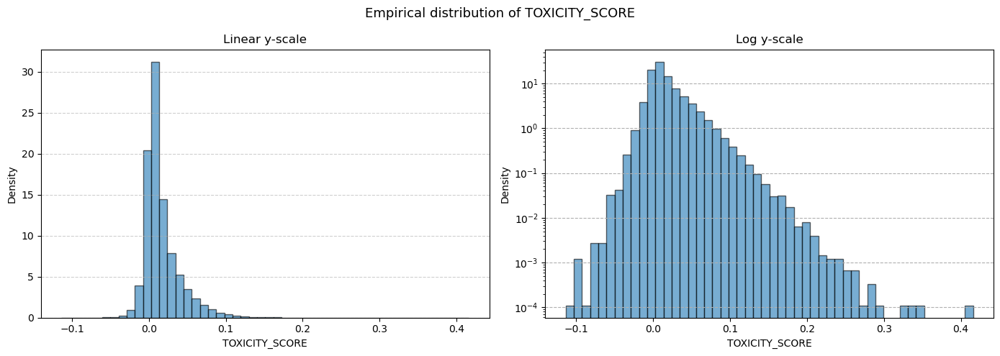

In [10]:
plot_empirical_distribution(interactions_df["TOXICITY_SCORE"], "TOXICITY_SCORE")

Empirically, the score falls within –0.1 to 0.4, reflecting real distributions in Reddit posts.

## 2.2 Toxicity binary classification

We now have a reliable, continuous measure of toxicity. But it's not necessarily easy to interpret directly... We would like to accompany this continuous metric with a binary classification: "Is this toxicity score value sufficiently high? In other words, is this message toxic?"

<div style="border: 2px solid #ff0000ff; border-radius: 10px; padding: 10px; display: inline-block; width: 90%; box-sizing: border-box;">
<code>TOXICITY_CAT</code>: categorical metric that classifies posts as non-toxic (0) or toxic (1), after passing a threshold on <code>TOXICITY_SCORE</code>. 
</div>

**Selecting the binary toxicity classification threshold**

The threshod above which messages are flagged as toxic is the quantile-75 of the toxicity scores distribution. That is, **we mark as significantly toxic the top 25% messages with highest score**. What motivates our choice?

- Toxic behavior is statistically rare — and tail-based thresholds reflect this. Online toxicity is considered to be heavy-tailed in the sense that most posts are neutral, while toxic ones are relatively rare and concentrated at the upper end of the distribution. Selecting the **upper quartile (top 25%)** isolates the **long tail of intense language** but ensures coverage of sufficiently frequent abusive content.
Thus, the 75th percentile is a natural and theoretically grounded boundary.

- 75th percentile ensures class balance suitable for downstream modeling. Binary classification tasks require a **non-trivial positive class** to avoid degenerate models.  
   Cutting at:
   - 90% → positive class too small (5–10%), sparse, high variance  
   - 50% → positive class too large, not aligned with toxicity rarity  

- The 75th percentile is conceptually aligned with “significant toxicity”. By definition, we want to classify only **strongly toxic** posts as toxic.  
Choosing the **top quartile** is a reliable way to identify posts with unusually high use of aggressive markers and atypical linguistic patterns. This makes toxicity classification interpretable and consistent across subreddits.

75% quantile threshold: 0.02368686868687879


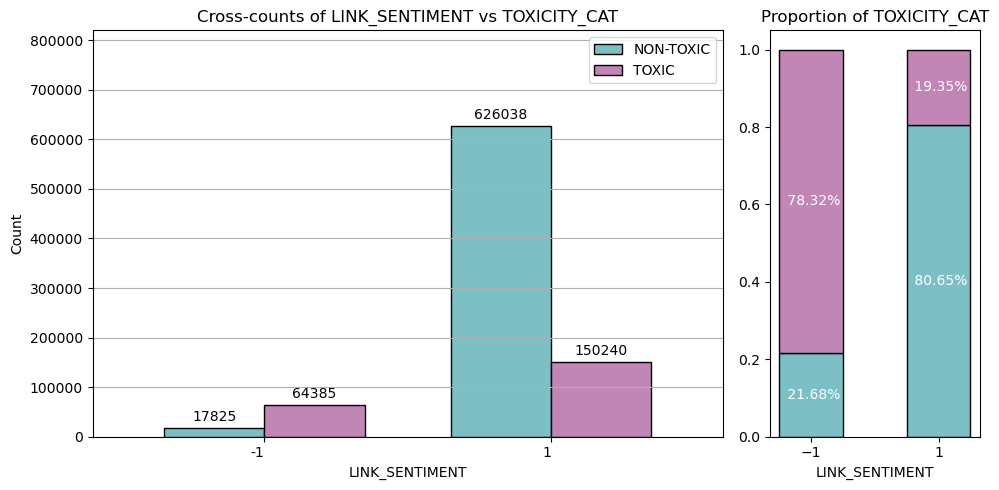

In [11]:
threshold_toxicity = interactions_df["TOXICITY_SCORE"].quantile(0.75)
print("75% quantile threshold:", threshold_toxicity)

interactions_df["TOXICITY_CAT"] = (interactions_df["TOXICITY_SCORE"] >= threshold_toxicity).astype(int)

cross_count_SENTIMENT_TOXICITY(interactions_df)

At first, it appears that the majority of toxic messages are actualy labeled positive, which is not desirable as we explicited that, in our context, toxicity only comes with negativity. 

However, looking at the **proportions** of toxicity in each sentiment class (right barplot), we see that around 78% of negative messages are labeled toxic, while only 19% of positive messages were. Negative messages are much more likely to be toxic (which makes sense based on the properties we retained to define toxicity).

In the next cell, we enforce the rule that only messages with negative sentiment (`LINK_SENTIMENT` = −1) can be classified as toxic (`TOXICITY_CAT` = 1). This decision is based on a conceptual definition of toxicity as hostile, harmful, or abusive discourse, which fundamentally requires a negative emotional valence. Although positive/neutral-sentiment messages may sometimes contain high levels of features like swearing or anger, classifying them as toxic would introduce significant false positives that do not align with the standard understanding of online harassment or abuse.

**Remark**

The continuous `TOXICITY_SCORE` is preserved even for the links that are ultimately filtered out by the sentiment check. This score serves as a crucial linguistic feature intensity metric, quantifying the sheer presence of aggressive or low-quality language features (e.g., swearing, anger, simplicity) independent of the link's overall "true" sentiment. By keeping the raw score, we retain valuable information for later analysis, such as comparing the distribution of strong language features across both toxic (negative sentiment) and non-toxic (positive sentiment) messages, which can reveal linguistic patterns related to intense discourse beyond just negative intent.

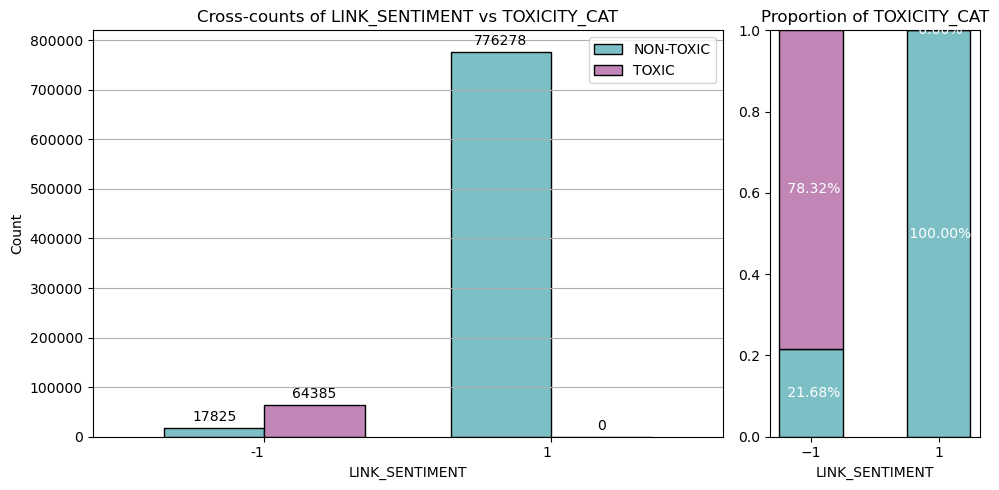

In [12]:
interactions_df["TOXICITY_CAT"] = ((interactions_df["TOXICITY_CAT"] == 1) & (interactions_df["LINK_SENTIMENT"] == -1)).astype(int)

# Sanity check (to verify elimination of false positives)
cross_count_SENTIMENT_TOXICITY(interactions_df)

Let's see how much toxic posts we detected over the entire period. The following plot aggregates over all subreddits and averages monthly, but acts as a quick sanity check to see if the count stays coherent over time.

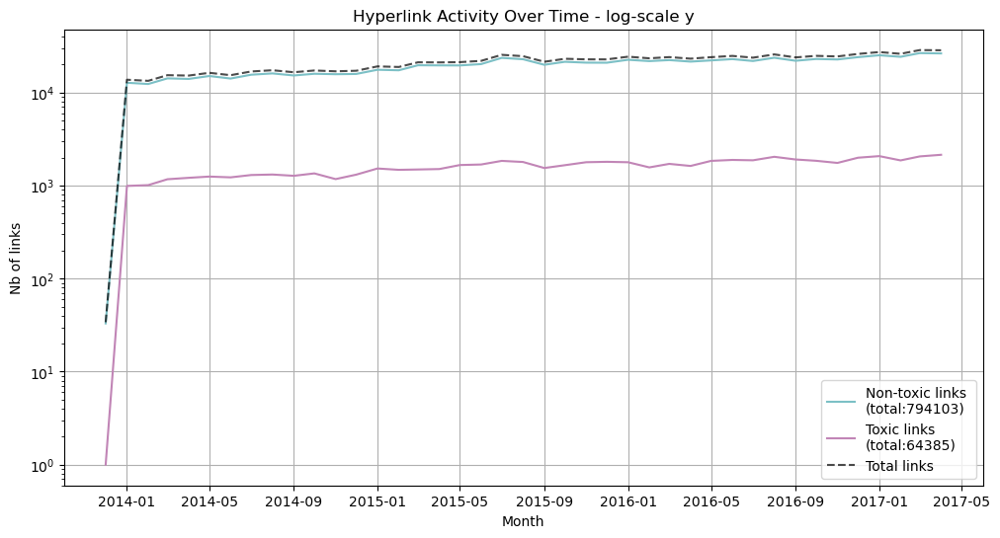

In [13]:
hyperlink_activity_over_time(interactions_df)

## 2.3 Mapping the distribution of toxicity

### Overall mean toxicity

To get an overall idea of whether we can detect clusters of toxic subreddits, we compute the mean toxicity score of the interactions going out of each subreddit over the whole time period of our dataset, and represent it on the map.

In [14]:
# Compute mean toxicity for each source subreddit from their outgoing interactions
mean_toxicity = (
    interactions_df.groupby("SOURCE_SUBREDDIT")["TOXICITY_SCORE"]
    .mean()
    .rename("mean_toxicity_score")
)

# Merge mean toxicity data with 2D embeddings
embeddings_with_toxicity = embeddings_with_topics.merge(
    mean_toxicity, left_on="SUBREDDIT", right_on="SOURCE_SUBREDDIT", right_index=True, how="left"
).fillna(0)

# Plot an interactive map of the embeddings with toxicity highlighted
plotly_embeddings(embeddings_with_toxicity, highlight="toxicity", write=False)

We can already see that some areas have a higher proportion of subreddits with a moderately high mean toxicity score (look at the controversial subjects area on the top right for example). 
This observation is very broad since it only considers the mean toxicity over the whole period (2.5 years): communities and bursts of toxicity should be easier to observe over a smaller time period, if selected correctly.

### Monthly evolution of toxicity 

We check whether we can decompose the data into monthly time series by taking advantage of the 'TIMESTAMP' column, still with the most active subreddits, and plot them using an animated map. 
We compute the monthly mean outgoing toxicity score of each subreddit to see their evolution with time.

In [15]:
ani_monthly = animate_toxicity(active_subs, filtered_embeddings_2d, freq='ME')
HTML(ani_monthly.to_jshtml())

This animation shows that no area of Reddit was spared from toxicity over the whole time period. We observe fluctuating toxicity scores for most subreddits, but also clusters who keep mostly toxic interactions throughout the whole time period (such as at the controversial subjects area again).

---
# Phase 3: Study of Propagation Types - Clustering & Injection in the Reddit Map

## Motivation

Understanding toxic behavior on Reddit requires more than just identifying which posts are toxic. Indeed, we need to understand the **temporal and behavioral patterns** that characterize different types of toxicity. Not all toxic subreddits behave the same way of acting and spreading through time .

Some communities may be **chronic aggressors** that consistently attack others over long periods, while others might be **episodic attackers** that have sudden bursts of toxic activity triggered by specific events. Similarly, some communities may act as **frequent victims** of incoming toxicity, while others engage in **reciprocal toxic exchanges** with specific adversaries. There may even be **dormant toxic communities** that have brief, intense periods of activity separated by long quiet intervals.

**The goal of this clustering analysis is to identify distinct temporal and behavioral patterns of toxicity** and not just sticking to simple binary classification (toxic vs. non-toxic). For this, we use a combination of:
- **Temporal features** (when and how often toxic events occur)
- **Role-aware features** (aggressor vs. victim behavior)  
- **Network features** (degree centrality, reciprocity)

we aim to classify subreddits into meaningful behavioral archetypes that reveal the **dynamics and rhythm** of toxic behavior over time.

<!-- This classification will help us:
1. **Understand toxicity propagation mechanisms**: Do certain behavioral patterns make communities more likely to spread toxicity?
2. **Identify intervention targets**: Should moderation efforts focus on chronic aggressors, episodic bursters, or vulnerable victims?
3. **Predict future toxic outbreaks**: Can we use these patterns to anticipate which communities are at risk of escalating toxic behavior? -->

This classification will help us:
1. **Characterize toxicity spread patterns**: How do different types of hate spread across Reddit? Which behavioral patterns are most common?
2. **Understand community roles and activity**: Are there more aggressors or victims? Can we identify hyperactive toxic members who drive most of the hostile interactions?
3. **Detect temporal dynamics**: Is there periodicity in toxic behavior? Do certain patterns follow cycles ?


By capturing the multidimensional nature of toxic behavior not just its presence, but its frequency, intensity, timing, and directionality, we can develop a better understanding of how toxicity manifests and evolves across the Reddit ecosystem.

In [16]:
df, umap_available, hdbscan_available, reducer_name = preliminary_control(interactions_df)

## 3.1 Features used for Clustering

In order to be able to cluster subreddits based on their toxic behavior, we first need to define relevant features that capture different aspects of toxicity dynamics. We focus on three main dimensions: temporal features, role-aware features, and network features.

### 3.1.1 Role Aware Temporal Features: Source vs Target Behavior

##### Why Separate Aggressor and Victim Roles?

Understanding toxic behavior on Reddit requires distinguishing between **who is sending** and **who is receiving** toxic content. A subreddit's role in the toxicity network, whether as an aggressor, a victim, or both, fundamentally shapes its behavioral pattern and requires different features to capture accurately.

**The key idea with an example**: A subreddit that sends 100 toxic messages and receives 10 is behaving very differently from one that sends 10 and receives 100, even though their total toxic interaction count is the same. To cluster subreddits correctly, we need to capture these distinct roles separately.

##### Why This Matters for Clustering

For clustering, we care not just about *how much* toxicity a subreddit is involved in, but *in which direction*. Two communities with the same total number of toxic interactions can look completely different if one mostly sends toxicity while the other mostly receives it.

By computing all temporal features separately for **source (aggressor)** and **target (victim)** roles, we can:
- Distinguish clear **aggressors**, **victims**, and **reciprocal hubs**;
- Preserve the **directional flow** of toxicity in the network, which is key for studying propagation.

This role-aware design ensures that a chronic aggressor and a frequent victim do not end up in the same behavioral archetype just because they share a similar total volume of toxic events.

We therefore compute all temporal features twice, once for source (outgoing toxic interactions) and once for target (incoming toxic interactions), giving us a complete picture of each subreddit's toxic behavior profile.


#### Source (Aggressor) Temporal Features

- **`src_tox_count`**: Total number of toxic interactions sent by the subreddit over the entire period. This measures the overall volume of toxic aggression.

- **`src_active_span_days`**: The time span (in days) between the first and last toxic interaction sent. This captures how long the subreddit has been actively sending toxic content.

- **`src_median_gap_days`**: The median number of days between consecutive toxic interactions sent. This indicates the typical waiting time between toxic outbursts.

- **`src_gap_cv`**: The coefficient of variation (CV) of the gaps between toxic events. A low CV indicates regular, periodic toxic behavior, while a high CV suggests irregular, sporadic bursts.

- **`src_max_30d_count`**: The maximum number of toxic interactions sent within any 30-day window. This identifies the intensity of the subreddit's worst toxic period.

- **`src_event_rate`**: The average rate of toxic events sent (toxic count / active span). This normalizes activity by duration, distinguishing between sustained and brief toxic phases.

- **`src_pct_events_recent`**: The percentage of toxic events that occurred in the recent portion of the observation period. This helps identify whether toxicity is increasing, decreasing, or stable over time.

#### Target (Victim) Temporal Features

- **`tgt_tox_count`**: Total number of toxic interactions received by the subreddit. This measures the overall volume of incoming toxicity.

- **`tgt_active_span_days`**: The time span (in days) between the first and last toxic interaction received. This captures how long the subreddit has been a target of toxic behavior.

- **`tgt_median_gap_days`**: The median number of days between consecutive toxic interactions received. This indicates the typical frequency of incoming attacks.

- **`tgt_gap_cv`**: The coefficient of variation of the gaps between received toxic events. This distinguishes between subreddits that receive steady harassment versus those targeted in irregular bursts.

- **`tgt_pct_events_recent`**: The percentage of received toxic events that occurred in the recent portion of the observation period. This helps identify whether a subreddit is becoming a more frequent target over time.

Together, these temporal features let us distinguish between chronic vs episodic activity, sustained vs event-triggered targeting, and escalating vs declining toxicity patterns.

In [17]:
# We build separate features for source (aggressor) and target (victim) roles
toxic_df = interactions_df[interactions_df["TOXICITY_CAT"] == 1].copy()
source_df, source_features = comp_source_features(toxic_df)

  SOURCE features computed for 6921 subreddits


In [18]:
target_df, target_features = comp_target_features(toxic_df)

  TARGET features computed for 5333 subreddits


### 3.1.2 Network Features

##### Why Network Structure Matters?

Beyond understanding when toxic behavior occurs (temporal features) and who is aggressor vs. victim (role-aware features), we need to understand the **network structure** of toxic interactions. Network features capture how subreddits are positioned and connected within the broader toxic interaction network, revealing patterns of isolation, centrality, and reciprocal relationships.

##### Network Metrics

- **`net_out_degree`**: The number of **distinct subreddits** that this subreddit has sent toxic messages to. This measures whether a subreddit targets a single adversary or spreads toxicity across many different communities. A high out-degree indicates a subreddit that engages in widespread toxic behavior.

- **`net_in_degree`**: The number of **distinct subreddits** that have sent toxic messages to this subreddit. This measures whether a subreddit is targeted by a single source or receives toxicity from many different communities. A high in-degree might indicate a controversial or polarizing subreddit.

- **`net_reciprocity`**: The proportion of toxic relationships that are **bidirectional** (subreddits that both send and receive toxic messages from each other). This captures **mutual toxic exchanges**. High reciprocity suggests active "toxic exchanges" rather than one-sided harassment.

##### Why Network Features Enable Better Clustering?

These features reveal fundamentally different behavioral patterns:

- **Isolated aggressors** (high out-degree, low in-degree, low reciprocity): Subreddits that attack many others but rarely receive toxicity back, potentially trolling or attacking communities.

- **Targeted victims** (low out-degree, high in-degree, low reciprocity): Subreddits that receive toxicity from many sources but don't retaliate, potentially controversial topics or vulnerable communities.

- **Adversarial communities** (balanced degrees, high reciprocity): Subreddits engaged in mutual toxic exchanges, potentially rival communities with ongoing conflicts, for example in sports with rival teams.

- **Toxic hubs** (high out-degree, high in-degree, moderate reciprocity): Central nodes in the toxic network that both spread and attract toxicity, potentially highly polarizing or contentious communities.

By combining network features with temporal and role-aware features, we capture the complete picture of how each subreddit participates in the toxic ecosystem.

In [19]:
out_degree, in_degree = compute_out_in_degree(source_df, target_df)

In [20]:
# We compute reciprocity for each subreddit
reciprocity = call_compute_reciprocity(source_df, target_df, toxic_df)

In [21]:
temporal_features = merge_all_features(source_features, target_features, out_degree, in_degree, reciprocity)


Total subreddits before filtering: 9752


/Users/cedriczanou/Desktop/MA3/ADA/ada-2025-project-adastra/src/utils/clustering_utils.py:424: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0' has dtype incompatible with datetime64[ns], please explicitly cast to a compatible dtype first.



## 3.2 Clustering Preprocessing

### 3.2.1 Filtering Low-Activity Subreddits

Given that our dataset spans approximately 2.5 years (roughly 900 days), we need to carefully handle edge cases where subreddits have very little toxic activity. Including subreddits with only a handful of toxic interactions would introduce several problems:

1. **Statistical unreliability**: Temporal features like median gap days, coefficient of variation, and event rates become meaningless or highly unstable when computed from very few data points. For example, a subreddit with only 2-3 toxic events cannot provide a reliable measure of behavioral patterns.

2. **Feature computation issues**: Many of our features require multiple events to be meaningful:
   - Gap CV (coefficient of variation) needs multiple gaps to measure consistency
   - Median gap requires at least several events to be representatives

3. **Noise amplification**: Subreddits with minimal activity often have extreme or outlier feature values that don't represent true behavioral patterns but rather random fluctuations.

4. **Practical relevance**: A subreddit with only a few toxic interactions over 2.5 years is not exhibiting meaningful toxic behavior patterns worth clustering. It can be classified as non-toxic with occasional isolated incidents.

##### Justifying the Threshold of 10 Toxic Events

We set the minimum threshold at **10 toxic events** based on the following considerations:

- **Clustering quality**: Empirically, including subreddits with fewer than 10 events tends to create outlier clusters dominated by noise rather than revealing meaningful behavioral archetypes. 10 represents a reasonable balance between retaining enough data for robust clustering while excluding statistically unreliable cases.

In [22]:
temporal_features = filter_low_activity(temporal_features, min_toxic_events=10)

Subreddits after filtering (>= 10 total toxic events): 1364


### 3.2.2 NaN Handling

After computing temporal and network features, we perform a quick sanity check to handle any missing values (NaNs) that may have appeared during feature computation. This ensures our feature matrix is complete and ready for clustering algorithms, which typically cannot handle missing values. This step validates data integrity before proceeding to feature scaling and dimensionality reduction.

In [23]:
temporal_features = temporal_nan_handling(temporal_features)
temporal_features = other_nan_handling(temporal_features)

### 3.2.3 Feature Correlation, Multicolinearity Analysis and Feature Scaling

When clustering temporal toxicity patterns, we face three interconnected challenges that can seriously undermine our results. 

First, many of our features are inherently correlated: for instance, subreddits with high toxic event counts naturally tend to have longer activity spans, and network centrality measures often move together. This multicollinearity biases distance-based algorithms like K-Means. 

Second, some of the features used shows a high skewness, with mega-subreddits generating orders of magnitude more events than typical communities. Without addressing this, a handful of outliers can dominate the entire clustering process. 

Finally, our features exist on wildly different scales: some measure days, others percentages, and still others raw counts-making direct comparison problematic.

Rather than treating these as isolated issues, we approach them systematically through a sequenced pipeline. Each step builds on the previous one, informed by the specific statistical properties of our features and the requirements of K-Means and PCA.

In [24]:
# We select features for clustering
feature_cols = [
    # Source (aggressor) features
    "src_tox_count",
    "src_active_span_days",
    "src_median_gap_days",
    "src_gap_cv",
    "src_max_30d_count",
    "src_event_rate",
    "src_pct_events_recent",
    # Target (victim) features
    "tgt_tox_count",
    "tgt_active_span_days",
    "tgt_median_gap_days",
    "tgt_gap_cv",
    "tgt_pct_events_recent",
    # Network features
    "net_in_degree",
    "net_out_degree",
    "net_reciprocity",
]

features = temporal_features[feature_cols].copy()

#### Feature Correlation

Before diving into multicollinearity correction, we need to understand which features are moving together and why. Pearson correlation analysis gives us this initial diagnostic view by detecting linear dependencies between feature pairs. When we see high pairwise correlations (defined here as |r| > 0.8), it's a red flag that two features might be measuring the same underlying temporal phenomenon.

This matters for several reasons:
1. Information redundancy means multiple features contribute overlapping variance to our principal components, which over-weights certain aspects of toxicity dynamics

2. Numerically, highly correlated features can create near-singular covariance matrices that make PCA decomposition unstable.

3. From an interpretation standpoint, when features move in lockstep, it becomes nearly impossible to attribute cluster characteristics to individual features with confidence.

In our temporal toxicity data, certain correlations tell intuitive stories. Subreddits with more toxic events (`src_tox_count`) naturally tend to have longer activity periods (`src_active_span_days`). Similarly, network centrality measures like `net_in_degree` and `net_out_degree` often co-vary in dense conflict networks, where highly connected nodes tend to be both targets and sources of toxicity. We also see mathematical dependencies between count-based features and their derived rates, which is expected given how these metrics are computed.

Computing correlations on raw features rather than transformed ones is deliberate. Raw correlations reflect the fundamental relationships in the data generation process: the actual mechanisms by which subreddits generate toxic interactions.

In [25]:
corr_matrix = compute_feature_correlations(features)


Highly correlated feature pairs (|r| > 0.8):
  src_tox_count <-> src_max_30d_count: r=0.814
  src_tox_count <-> src_event_rate: r=0.810
  src_tox_count <-> net_out_degree: r=0.955
  src_max_30d_count <-> net_out_degree: r=0.848
  tgt_tox_count <-> net_in_degree: r=0.984


#### VIF Analysis

Correlation analysis shows us pairwise relationships, but it misses a crucial aspect of multicollinearity: features can be linearly dependent on combinations of other features, even when no single pairwise correlation is particularly high. This is where Variance Inflation Factor (VIF) helps us. VIF quantifies multicollinearity across all features simultaneously by measuring how much each feature's variance is "inflated" due to its linear dependence on other predictors. For a feature $X_j$, we compute:

$$
\text{VIF}_j = \frac{1}{1 - R^2_j}
$$

where $R^2_j$ comes from regressing $X_j$ on all other features. 

The interpretation is the following: VIF < 5 indicates low multicollinearity (acceptable), values between 5 and 10 suggest moderate issues worth investigating, and VIF > 10 signals severe multicollinearity where feature removal becomes necessary. Removing redundant features gives us sparse, interpretable profiles where each retained feature contributes genuinely unique information.

The strategy used is iterative: remove the feature with the highest VIF, recalculate VIF scores for the remaining features (since multicollinearity relationships change when a feature drops out), and repeat until all VIF values fall below 10. This ensures we are always removing the most redundant feature first (the one with maximum $R^2$ when predicted by all others) and that our final feature set has minimal redundancy.

**Why do we compute VIF on raw data ?**

We compute VIF on raw features because this identifies structural multicollinearity inherent to how toxicity dynamics actually work. This makes interpretability higher than when transforming, which could introduce artificial correlations. Since log and winsorization transformations are monotonic, they also preserve the correlation structure. Cleaning up multicollinearity before transformation simplifies our pipeline and ensures all subsequent preprocessing steps operate on a cleaner feature space.

Note: Please deploy the print cell under the following cell (i.e., make the cell a "scrollable element") to see the VIF scores at each iteration

In [26]:
vif_scores = compute_vif(features)
feature_cols, features, features_reduced, removed_features = remove_high_vif_features(features, threshold=10.0)
final_vif_scores = verify_final_vif(features)


Variance Inflation Factor (VIF) scores:
  (VIF > 10 = severe multicollinearity, VIF > 5 = moderate)
  net_in_degree                 :   34.45 HIGH
  tgt_tox_count                 :   33.03 HIGH
  net_out_degree                :   16.00 HIGH
  src_tox_count                 :   14.56 HIGH
  src_max_30d_count             :    6.68 MOD
  src_event_rate                :    3.52 LOW
  src_gap_cv                    :    3.12 LOW
  tgt_active_span_days          :    2.44 LOW
  tgt_gap_cv                    :    2.07 LOW
  src_active_span_days          :    2.06 LOW

Removing features with VIF > 10.0:
  Starting with 15 features
  Iteration 1: Removing 'net_in_degree' (VIF=34.45)
  Iteration 2: Removing 'net_out_degree' (VIF=15.97)

 All features now have VIF <= 10.0

Feature reduction summary:
  Features removed: 2
  Features remaining: 13

Final VIF scores for all 13 remaining features:
  (All should be ≤ 10.0 for acceptable multicollinearity)
  src_tox_count                 :    5.96 MOD
  

#### Log-Transformation

With multicollinearity addressed, we address the distributional challenge posed by count-based features. Temporal toxicity counts show heavy skewness typical of power-law distributions. This creates three main problems for clustering.

First, they dominate distance calculations. Euclidean distance is extremely sensitive to large absolute differences. This single dimension overwhelms differences in all other features, essentially reducing our multi-dimensional clustering to a one-dimensional sort by activity level.

Second, the presence of outliers compresses the distribution for everyone else. Therefore, the algorithm effectively loses discriminative power for the majority of our data.

Third, PCA makes implicit assumptions about how features contribute to total variance. Extreme outliers artificially inflate the variance of count features, causing them to dominate the first principal components even when their actual information content might be lower than other features.

Log transformation addresses all of these issues through variance stabilization. We use $\log(1 + X)$ rather than $\log(X)$ to handle zero values:

$$
X_{\text{transformed}} = \log(1 + X)
$$

This transformation symmetrizes our distributions, pushing skewed data toward approximate Gaussianity. While PCA doesn't strictly require normality, distance-based clustering performs better when features aren't wildly asymmetric.

To determine which features require log-transformation, we systematically inspected the distribution of each feature using Microsoft's Data Wrangler tool, a visual data exploration tool that generates histograms and summary statistics. This inspection revealed pronounced right skewness across our count-based and duration-based features. Based on these distributional diagnostics, we apply log-transformation to the following features:

```python
log_cols = [
    "src_tox_count", "src_active_span_days", "src_median_gap_days", "src_gap_cv", 
    "src_max_30d_count", "src_event_rate",
    "tgt_tox_count", "tgt_active_span_days", "tgt_median_gap_days", "tgt_gap_cv",
    "net_in_degree", "net_out_degree", "net_reciprocity"
]
```

Notably, we exclude certain features from log-transformation despite their numerical nature. Percentages like `src_pct_events_recent` and `tgt_pct_events_recent` are already bounded [0, 100] and showed relatively symmetric distributions in our inspection. The difference metric `net_toxicity` can be negative (when a subreddit receives more toxicity than it sends), making log-transformation mathematically impossible. Additionally, this feature also has a relatively symmetric distribution. These features receive different treatments in our preprocessing pipeline.

In [27]:
features = log_transform(features)

#### Winsorization

Log transformation handles count features, but percentage-based and ratio-based features need a different approach. These features are already bounded and relatively symmetric, yet they can still contain outliers within their valid ranges that pose problems for clustering.

We use winsorization to address this issue. Rather than removing outliers or transforming the entire distribution, we cap extreme values at a specified percentile:

$$
X_{\text{winsorized}} = \begin{cases}
X & \text{if } X \leq p_{\text{threshold}} \\
p_{\text{threshold}} & \text{if } X > p_{\text{threshold}}
\end{cases}
$$

For the selected features, we cap at the 90th percentile, which controls the top 10% of extreme values while preserving the full range of the bottom 90%.

We apply winsorization specifically to features that weren't log-transformed, avoiding redundant preprocessing that could distort our data in unpredictable ways.

In [28]:
features = apply_winsorization(features, 0.90)

Winsorized src_pct_events_recent at 90th percentile: 50.00
Winsorized tgt_pct_events_recent at 90th percentile: 50.00


#### Detect Mega-Subreddits based on Raw Features (Non-Transformed)

Some subreddits operate on a completely different scale than typical communities (orders of magnitude difference). These mega-subreddits aren't just statistical outliers; they're substantively different entities with high influence on Reddit's overall toxicity landscape.

**Why do we use raw features to detect mega-subreddits?**

Detecting these mega-subreddits requires working with raw, untransformed data. The 99th percentile threshold that flags mega-subreddits needs to reflect real-world activity levels. After log-transformation, these thresholds fail to traduce this activity accurately. The concept of a "mega-subreddit" is inherently about extreme absolute activity in the original measurement units, not about being a statistical outlier in a normalized distribution.

Moreover, standard scaling (which comes next in our pipeline) destroys real-world scale information entirely. After scaling, every feature has mean zero and standard deviation one. This makes interpretability and comparison harder.

Our implementation:

```python
mega_mask = (
    (temporal_features["net_in_degree"] > temporal_features["net_in_degree"].quantile(0.99)) |
    (temporal_features["net_out_degree"] > temporal_features["net_out_degree"].quantile(0.99)) |
    (temporal_features["total_tox_count"] > temporal_features["total_tox_count"].quantile(0.99))
)
```

Mega-subreddits don't get removed from clustering, they represent real, important entities in Reddit's toxicity network. Instead, we flag them with a binary `is_mega` feature (0 or 1) that gets added to our clustering feature set. This allows the algorithm to naturally separate mega-subreddits into their own clusters if their overall temporal pattern differs from typical subreddits, while still allowing mega-subreddits with similar temporal dynamics to cluster with smaller communities exhibiting the same pattern.

In [29]:
features, temporal_features, feature_cols = detect_mega_subreddits(features, temporal_features, feature_cols)

  Total subreddits for clustering: 1364
  Mega-subreddits (>99th percentile): 26
    These will be included in clustering and labeled for interpretation

  Top 10 mega-subreddits by total activity:
    subredditdrama: total=8244, src=7550, tgt=694, in_deg=266, out_deg=1556
    bestof: total=3016, src=2828, tgt=188, in_deg=96, out_deg=970
    askreddit: total=2641, src=61, tgt=2580, in_deg=888, out_deg=35
    drama: total=2464, src=2239, tgt=225, in_deg=93, out_deg=710
    circlebroke2: total=1649, src=1599, tgt=50, in_deg=23, out_deg=348
    worldnews: total=1384, src=12, tgt=1372, in_deg=415, out_deg=12
    news: total=1359, src=11, tgt=1348, in_deg=385, out_deg=10
    shitpost: total=1284, src=1222, tgt=62, in_deg=16, out_deg=323
    todayilearned: total=1227, src=146, tgt=1081, in_deg=371, out_deg=75
    pics: total=1130, src=2, tgt=1128, in_deg=400, out_deg=2


#### Standard Scaling

After all these preprocessing steps, our features still exist on wildly incompatible scales. This scale heterogeneity creates fundamental problems for both PCA and K-Means, making standardization essential.

Standard scaling transforms each feature to zero mean and unit variance via z-score normalization:

$$
X_{\text{scaled}} = \frac{X - \mu}{\sigma}
$$

where $\mu$ is the feature mean and $\sigma$ is its standard deviation. Every feature gets centered at zero and rescaled so one standard deviation equals one unit.

This matters for PCA, as it decomposes the feature covariance matrix. Features with large raw variances—like `src_active_span_days` naturally dominate the covariance structure over low-variance features like our binary `is_mega` flag. Without standardization, the first principal component would essentially become "the active span direction", obliterating the multi-dimensional structure we preserved through VIF reduction.

K-Means amplifies this problem through Euclidean distance. A 100-day difference in `src_active_span_days` dominates a 2-unit difference in log-transformed `src_tox_count`, even though both might be equally meaningful. Standardization equalizes contributions.

**Why StandardScaler?**

We use StandardScaler rather than alternatives like RobustScaler (median/IQR-based) or MinMaxScaler ([0,1] squashing) because we've already handled outliers through log transformation and winsorization. StandardScaler respects the full distribution, while MinMaxScaler would destroy information about relative spread: a tightly clustered feature and a widely dispersed one would both flatten to [0, 1].

**Why do we apply scaling last?**

- Scaling before log transformation would standardize right-skewed, outlier-dominated distributions where mean and standard deviation are distorted. 
- Scaling before VIF would be computationally inefficient. 
- Scaling before winsorization creates features that aren't properly standardized after capping.

In [30]:
# We replace any remaining inf/nan values before scaling
features = handle_inf_nan(features)
X_scaled = standard_scaling(features)

## 3.3 Feature Space Reduction through PCA

### 3.3.1 PCA Motivation

#### Why PCA After VIF?

After removing highly correlated features through VIF (Variance Inflation Factor) analysis, we still have 14 features remaining. While multicollinearity has been addressed, we can further reduce dimensionality using Principal Component Analysis (PCA) to create a more compact and efficient feature space for clustering.

#### What PCA Does

PCA transforms our VIF-cleaned features into a smaller set of **principal components** that capture the maximum variance in the data. Each principal component is a linear combination of the original features, ordered by the amount of variance they explain. This allows us to represent our high-dimensional data in fewer dimensions while preserving most of the meaningful variation.

#### Variance Threshold Selection

We set a **variance threshold of 80%**, meaning we retain only the principal components needed to explain at least 80% of the total variance in our feature space. This is a standard choice that balances:

- **Information preservation**: Retaining most of the meaningful patterns in the data
- **Dimensionality reduction**: Creating a more compact representation that reduces noise and computational complexity
- **Clustering efficiency**: Working with fewer dimensions improves clustering algorithm performance

In [31]:
n_components_optimal, feature_importance_df = analyze_pca_components(feature_cols, X_scaled, variance_threshold=0.80)


Analysis Results:
  Total components: 14
  Components for 80% variance: 6
  Variance explained by first 6 PCs: 84.5%
  DIMENSIONALITY REDUCTION: Clustering will use 6D PC space instead of 14D feature space

Variance explained by first 10 components:
  PC 1:  30.1% (cumulative:  30.1%) ███████████████ <- RETAINED
  PC 2:  19.9% (cumulative:  50.0%) █████████ <- RETAINED
  PC 3:  12.5% (cumulative:  62.5%) ██████ <- RETAINED
  PC 4:   9.0% (cumulative:  71.4%) ████ <- RETAINED
  PC 5:   7.2% (cumulative:  78.6%) ███ <- RETAINED
  PC 6:   5.8% (cumulative:  84.5%) ██ <- RETAINED
  PC 7:   5.6% (cumulative:  90.0%) ██ (discarded)
  PC 8:   3.8% (cumulative:  93.8%) █ (discarded)
  PC 9:   2.2% (cumulative:  96.0%) █ (discarded)
  PC10:   1.8% (cumulative:  97.7%)  (discarded)

  Top 10 most contributing original features to 6 retained PCs:
    tgt_active_span_days          :   8.8%
    src_median_gap_days           :   8.4%
    src_event_rate                :   8.1%
    tgt_gap_cv        

### 3.3.1 PCA Interpretation

The PCA analysis reveals:

- **Number of components**: The optimal number of principal components needed to reach the 80% variance threshold is 6 components. With these 6 components we manage to explain 84.5% of the total variance in the data.(More detal can be seen on the ouput above)
- **Variance explained**: Each component's contribution to the total variance, with the first few components capturing the majority of the variation

This dimensionality reduction creates a more efficient feature space for clustering while preserving the essential structure needed to identify distinct toxic behavior archetypes.

## 3.4 Clustering with KMeans

Now that we have a reduced feature space from PCA, we can apply clustering algorithms to identify distinct behavioral archetypes among subreddits based on their toxic activity patterns.

We apply the **K-Means clustering algorithm** to the PCA-transformed feature space. K-Means partitions the data into K clusters by minimizing the within-cluster variance, effectively grouping subreddits with similar toxic behavior patterns together. K-Means is well-suited for our PCA-transformed, standardized features, as it efficiently handles continuous data in Euclidean space and produces interpretable cluster centroids. Additionally, K-Means scales well computationally, allowing for rapid iteration and experimentation when determining the optimal number of clusters.

### 3.4.1 Optimal K Selection

##### Why Finding the Optimal K is Critical?

K-Means clustering is **heavily dependent on the choice of K** (the number of clusters). Unlike hierarchical or density-based methods, K-Means requires us to specify K in advance, and this choice fundamentally determines:

- **Cluster granularity**: Too few clusters (low K) merge distinct behavioral patterns together, losing important distinctions. Too many clusters (high K) create artificial subdivisions that don't represent meaningful differences.
- **Interpretability**: The clusters should correspond to interpretable toxic behavior archetypes. An inappropriate K leads to either overly broad or overly narrow groupings.
- **Model performance**: The quality of clustering, measured by both compactness (how tight clusters are) and separation (how distinct clusters are from each other), varies dramatically with K.

Therefore, selecting the optimal K is not arbitrary, it requires systematic evaluation using multiple validation metrics.

#### 3.4.1.1 Evaluation Metrics

We evaluate different values of K using two complementary metrics:

##### Silhouette Score
The **silhouette score** measures how well each point fits within its assigned cluster compared to other clusters. For a data point $i$ in cluster $C_i$:

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

where:
- $a(i)$ = average distance from point $i$ to all other points in the same cluster $C_i$ (measures **cohesion** or intra-cluster tightness)
- $b(i)$ = average distance from point $i$ to all points in the closest other cluster (measures **separation** or inter-cluster distance)

The silhouette score ranges from **-1 to +1**:
- **$s(i) \approx 1$**: Point is well-matched to its cluster and far from neighboring clusters (ideal)
- **$s(i) \approx 0$**: Point is on the boundary between two clusters (ambiguous assignment)
- **$s(i) < 0$**: Point might be assigned to the wrong cluster

The **overall silhouette score** is the mean across all points:

$$\text{Silhouette} = \frac{1}{n} \sum_{i=1}^{n} s(i)$$

Higher silhouette scores indicate better-defined, well-separated clusters.


##### Balance Term

The **balance term** measures how evenly data points are distributed across clusters. Highly imbalanced clusters (one cluster with 90% of points and others with 1-2% each) often indicate poor clustering quality, as the algorithm may be creating "outlier" clusters rather than meaningful behavioral groups.

We compute balance as the **ratio between the smallest and largest cluster sizes**:

$$\text{Balance} = \frac{\text{size of smallest cluster}}{\text{size of largest cluster}}$$

This ratio ranges from **0 to 1**:
- **Balance ≈ 1**: Clusters are perfectly balanced (equal sizes)
- **Balance ≈ 0**: Highly imbalanced clustering (one very large cluster and very small others)

**Higher balance scores** (closer to 1) indicate more evenly distributed clusters, which is generally preferable for interpretable clustering. A very low balance score suggests that K-Means is creating one dominant cluster with several tiny "outlier" clusters, which typically doesn't reflect meaningful behavioral distinctions.

#### 3.4.1.2 Cluster Stability Validation

K-Means is sensitive to initialization and can converge to different local optima depending on the random starting positions of centroids. To ensure our optimal K produces **robust and stable** clusters, we employ **bootstrap resampling** with stability validation:

1. **For each candidate K** (K = 2, 3, 4, ..., 10):
   - Run K-Means **100 times** with different random initializations
   - For each pair of runs, compute the **Adjusted Rand Index (ARI)** to measure cluster assignment consistency
   
2. **Stability Assessment**:
   - The **ARI** measures the similarity between two clustering results, adjusting for chance agreement
   - ARI ranges from -1 to 1, where 1 indicates perfect agreement, 0 indicates random clustering, and negative values indicate worse-than-random agreement
   - Calculate the **mean ARI** across all pairwise comparisons to assess overall stability
   - High mean ARI (close to 1) indicates that different initializations consistently produce the same cluster assignments

3. **Visual Validation**:
   - Print the distribution of ARI scores for each K value
   - Visually confirm that the chosen K exhibits consistently high ARI scores
   - Low variance in ARI scores confirms that the clustering is stable and reproducible

This validation ensures that our chosen K produces **consistent, reproducible clusters** rather than artifacts of random initialization. A K value with low or highly variable ARI scores indicates instability and should be avoided, even if other quality metrics appear favorable.

In [32]:
X_pca, cluster_labels, cluster_method, best_k, best_kmeans = compute_optimal_k(features, X_scaled, n_components_optimal)


Evaluating k values with 100 bootstrap samples per k...
  Testing k=2...
    Silhouette: 0.301, Balance: 0.465, Stability (ARI): 0.961 ± 0.043
  Testing k=3...
    Silhouette: 0.362, Balance: 0.232, Stability (ARI): 0.837 ± 0.257
  Testing k=4...
    Silhouette: 0.386, Balance: 0.311, Stability (ARI): 0.950 ± 0.048
  Testing k=5...
    Silhouette: 0.383, Balance: 0.052, Stability (ARI): 0.979 ± 0.020
  Testing k=6...
    Silhouette: 0.387, Balance: 0.064, Stability (ARI): 0.971 ± 0.018
  Testing k=7...
    Silhouette: 0.396, Balance: 0.081, Stability (ARI): 0.974 ± 0.016
  Testing k=8...
    Silhouette: 0.388, Balance: 0.096, Stability (ARI): 0.953 ± 0.025
  Testing k=9...
    Silhouette: 0.391, Balance: 0.037, Stability (ARI): 0.916 ± 0.080
  Testing k=10...
    Silhouette: 0.368, Balance: 0.048, Stability (ARI): 0.930 ± 0.049

Selecting best KMeans configuration...
  Selection criterion: 40% silhouette + 60% bootstrap stability

  Selected: k=4
    Silhouette: 0.386
    Balance: 0.3

#### 3.4.1.3 Determinig the Optimal K

The optimal K is selected as the value that:
1. Maximizes the silhouette score (cluster quality)
2. Maintains reasonable cluster balance (no extreme imbalances) 
3. Demonstrates high stability across bootstrap runs (high ARI with low variance)
4. Produces interpretable behavioral archetypes (qualitative check)

In our case , after evaluating K values from 2 to 10, we find that **K=4** provides the best trade-off:
- High mean silhouette score (~0.4), indicating well-defined clusters
- Acceptable balance (~0.3), avoiding extreme imbalances
- High stability (mean ARI = 0.942 +/- 0.046), showing consistent cluster assignments across runs

This systematic approach ensures our clustering is both statistically sound and practically meaningful for understanding toxic behavior patterns on Reddit.

### 3.4.2 Comprehensive Statistical Cluster Validation

Having identified temporal toxicity clusters through K-Means in PCA-reduced space, we face a critical question: are these clusters statistically meaningful, or have we imposed arbitrary partitions on continuous variation? Bootstrap validation addresses reproducibility, but it doesn't tell us whether clusters are well-separated, internally cohesive, or different on the features that defined them. This is the reason why comprehensive statistical validation is performed.

We adopt a triangulation strategy using three complementary validation approaches: two geometric quality indices that quantify cluster separation and cohesion from different mathematical perspectives, and a statistical hypothesis testing framework that assesses whether clusters differ substantively on the features we care about. Agreement across these metrics provides robust evidence of clustering quality whereas disagreement flags potential issues that deserve further investigations.

This matters because our clusters will inform subsequent analyses: identifying "patient zero" subreddits that highly contribute to toxic behaviors and characterizing network positions associated with different temporal patterns. If our clusters are artifacts rather than genuine patterns in the data, these analyses become unreliable.

#### 3.4.2.1 Davies-Bouldin Index

The Davies-Bouldin (DB) Index quantifies the "worst-case cluster overlap" by identifying, for each cluster, its most similar neighbor and computing the ratio of within-cluster to between-cluster distances. Formally, for cluster $C_i$ with centroid $\mu_i$ and average distance to centroid $S_i$, we compute similarity with cluster $C_j$ as:

$$
R_{ij} = \frac{S_i + S_j}{d(\mu_i, \mu_j)}
$$

where $d(\mu_i, \mu_j)$ is the distance between cluster centroids. The DB Index is then:

$$
\text{DB} = \frac{1}{k} \sum_{i=1}^{k} \max_{j \neq i} R_{ij}
$$

This metric averages across all clusters the maximum similarity each has with any other cluster. Lower values indicate better clustering (clusters are compact (small $S_i$) and well-separated (large $d(\mu_i, \mu_j)$), which makes the ratio small).

**Why DB Index for temporal toxicity clustering?** 

It directly addresses a key concern: are our temporal patterns sufficiently distinct, or do they blur together? When DB < 1.0, it tells that average within-cluster spread is smaller than typical between-cluster separation, which is a good sign that clusters occupy distinct regions of the temporal feature space. Values above 2.0 suggest substantial overlap, where subreddits in different clusters might be more similar to each other than to their cluster-mates.

The DB Index is particularly sensitive to cluster shape irregularities and size imbalances, both of which we expect in toxicity data. Mega-subreddits might form tight, isolated clusters due to their extreme activity levels, while moderate-activity subreddits might exhibit more diffuse patterns. DB Index captures whether this heterogeneity undermines cluster quality or whether our preprocessing successfully created a space where meaningful patterns dominate over scale differences.

In our implementation, DB Index operates in the same PCA-reduced space where we performed clustering. This ensures consistency as we're validating cluster quality in the actual geometric space where K-Means made its distance calculations.

#### 3.4.2.2 Calinski-Harabasz Score

The Calinski-Harabasz (CH) Score, also called the Variance Ratio Criterion, takes a complementary approach by decomposing total variance into between-cluster and within-cluster components. For $k$ clusters with $n$ total points, it computes:

$$
\text{CH} = \frac{\text{SS}_{\text{between}} / (k-1)}{\text{SS}_{\text{within}} / (n-k)}
$$

where $\text{SS}_{\text{between}}$ measures variance of cluster centroids around the global mean (weighted by cluster size), and $\text{SS}_{\text{within}}$ measures variance of points around their cluster centroids. Higher CH scores indicate that clusters are well-separated (high between-cluster variance) and internally cohesive (low within-cluster variance).

**Why complement DB Index with CH Score?** 

They address different potential issue. DB Index identifies problematic cluster pairs with excessive overlap, but it might miss cases where all clusters are equally poor (poorly separated but with no single worst-case pairing dominating). CH Score captures overall variance partitioning quality and rewards configurations that explain high variance through cluster assignments.

Moreover, DB Index uses centroid-based distances while CH Score uses variance decomposition. For non-spherical clusters, which we might get if temporal toxicity patterns present complex, multi-dimensional structure, these can give different signals. Agreement between DB and CH provides a stronger evidence than either alone that clusters are genuine.

In our temporal toxicity context, CH Score addresses whether our clustering reduces within-group heterogeneity. If subreddits in the same cluster exhibit wildly different temporal patterns, within-cluster variance stays high and CH Score remains low. High CH scores (typically hundreds or well-separated clusters) indicate that knowing a subreddit's cluster assignment substantially reduces uncertainty about its temporal toxicity dynamics.

The interpretation is the following: CH Score acts like an F-statistic from ANOVA, comparing explained variance (due to cluster differences) to unexplained variance (within-cluster variation). Just as we want high F-statistics in regression to indicate meaningful predictors, we want high CH scores to indicate meaningful clusters.

#### 3.4.2.3 Kruskal-Wallis H-test

Geometric quality metrics like DB and CH assess cluster structure globally, but they don't tell us whether clusters actually differ on the specific temporal features we engineered. A clustering could achieve low DB Index by separating on a single dominant feature (say, total event count) while failing to discriminate on other meaningful dimensions (temporal patterns, network reciprocity, gap variability). The Kruskal-Wallis H-test addresses this by testing each feature individually for significant differences across clusters.

The test is non-parametric—it ranks all observations, then tests whether mean ranks differ across clusters:

$$
H = \frac{12}{n(n+1)} \sum_{i=1}^{k} \frac{R_i^2}{n_i} - 3(n+1)
$$

where $R_i$ is the sum of ranks for cluster $i$ with $n_i$ members. Under the null hypothesis that all clusters have the same distribution for a given feature, $H$ follows a chi-squared distribution with $k-1$ degrees of freedom.

**Why non-parametric testing?** 

Even after log transformation, our temporal features may not satisfy normality assumptions required by parametric tests like ANOVA. Kruskal-Wallis, which tests rank differences rather than mean differences, remains valid regardless of these distributional quirks.

We apply this test to every feature in our clustering space, asking: do clusters significantly differ on `src_event_rate`? On `tgt_gap_cv`? On `net_reciprocity`? Each test produces a p-value indicating the probability of observing such rank differences if clusters were randomly assigned.

**Multiple testing correction via Bonferroni adjustment**

With multiple features, we face the multiple comparisons problem: even under the null hypothesis of no true differences, we'd expect 5% of tests to show p < 0.05 by chance alone. We adopt a conservative Bonferroni-corrected threshold of $\alpha = 0.05 / n_{\text{optimal features}}$, requiring p-values well below 0.05 to declare significance. This controls the family-wise error rate, ensuring that our significant results aren't false discoveries.

**Effect size via eta-squared approximation**

Statistical significance doesn't equal practical importance: with large sample sizes, even tiny differences become "significant." We complement p-values with eta-squared ($\eta^2$), which estimates the proportion of variance in each feature attributable to cluster membership:

$$
\eta^2 \approx \frac{H - k + 1}{n - k}
$$

Values near 0 indicate that cluster membership explains negligible feature variance (practically meaningless even if statistically significant). Values above 0.1-0.2 indicate moderate-to-large effects where cluster assignment substantially predicts feature values.

**Interpreting the results**: We report two different summaries:
1. **Proportion of significant features**: If 90% of features pass Bonferroni-corrected significance, clusters differ meaningfully across nearly all dimensions we measured. If only 30% are significant, clusters might be driven by a subset of features while being indistinguishable on others. This shows that the clustering didn't capture the full multi-dimensional structure we engineered.

2. **Top discriminative features by effect size**: Ranking features by $\eta^2$ reveals which temporal characteristics most strongly differentiate clusters. For instance if `src_event_rate` and `src_pct_events_recent` dominate, our clusters primarily reflect aggression intensity and recency. If network features like `net_in_degree` and `net_reciprocity` rank highest, clusters capture network position and mutual conflict patterns.

**Why this matters for interpretation**: These discriminative features become the basis for assigning interpretable labels to clusters. A cluster with significantly high `src_tox_count`, low `src_median_gap_days`, and high `src_pct_events_recent` might be labeled "chronic aggressors", which describes subreddits that consistently and recently emit toxic content with short gaps between events.

In [33]:
validation_results = validate_clusters_statistical(X_pca, features, cluster_labels, feature_cols)


Clustering Quality Metrics:
  Davies-Bouldin Index: 1.099
  Calinski-Harabasz Score: 556.5

Top 10 most discriminative features (by effect size):
   1. src_tox_count                 : η²=0.741, p=8.86e-219
   2. src_max_30d_count             : η²=0.683, p=1.19e-201
   3. src_event_rate                : η²=0.673, p=8.66e-199
   4. src_pct_events_recent         : η²=0.552, p=5.96e-163
   5. src_median_gap_days           : η²=0.521, p=5.78e-154
   6. tgt_tox_count                 : η²=0.515, p=4.80e-152
   7. src_active_span_days          : η²=0.456, p=7.84e-135
   8. src_gap_cv                    : η²=0.437, p=3.06e-129
   9. tgt_gap_cv                    : η²=0.431, p=1.75e-127
  10. tgt_active_span_days          : η²=0.428, p=1.82e-126

Significant features (p < 0.0.05/len(feature_cols)): 14/14


Once we have performed all of the above steps, we can assemble our dataframe with cluster labels and proceed to identify and analyze different toxicity patterns.

In [34]:
result_df, cluster_summary = assemble_results_dataframe(features, feature_cols, cluster_labels, temporal_features, reducer_name, cluster_method, X_pca)


Reducer: UMAP | Clustering: KMeans (k=4, silhouette=0.386, stability=0.950)
Clustering Space: 6D PC space (from 14 original features)

Cluster sizes:
cluster
1    636
2    302
0    228
3    198
Name: n_subreddits, dtype: int64

Cluster Balance Analysis:
  Largest cluster: 636 (46.6%)
  Smallest cluster: 198 (14.5%)
  Imbalance ratio: 3.2x


### 3.4.3 Toxicity Pattern Classification

K-Means assigns each subreddit a numeric cluster label (0, 1, 2, ...), but these labels carry no inherent meaning. Cluster 0 could be chronic aggressors or occasional victims: we can't tell from the number alone.

Temporal pattern classification bridges this gap by mapping clusters to interpretable archetypes: **chronic**, **bursty**, and **occasional** patterns. These labels convey temporal structure: consistent versus irregular versus infrequent. This makes results accessible and enables comparison across communities. Rather than saying "subreddits in Cluster 2," we say "chronic aggressors".

This classification is **role-aware**: we classify aggressors based on their source features (`src_*`) and victims based on their target features (`tgt_*`). A subreddit might be a chronic aggressor (high `src_tox_count`, low `src_median_gap_days`) but only an occasional victim (low `tgt_tox_count`, high `tgt_median_gap_days`). Collapsing these into a single pattern would supress the asymmetry in toxicity dynamics, which is precisely what our role-aware feature engineering was designed to preserve.

**Classification Scheme: Operationalizing Temporal Archetypes**

We define three temporal patterns based on combinations of event frequency, gap regularity, and burst intensity. The thresholds use data-driven tertile splits, ensuring patterns reflect the distributional differences of our dataset:

**Chronic Pattern**: Sustained, Consistent Toxicity
- **High count** (above 66th percentile): Many toxic events, indicating sustained activity
- **Low gap CV** (below 33rd percentile): Regular, consistent gaps between events
- **Interpretation**: Subreddits engaged in ongoing toxicity with high rhythm. These communities exhibit persistent conflict behavior, not an episodic one.

**Bursty Pattern**: Intense Episodic Spikes
- **High 30-day maximum** (above 66th percentile): Concentrated activity in short windows
- **High gap CV** (above 66th percentile): Irregular gaps, mixing long quiet periods with intense bursts
- **Interpretation**: Subreddits with sporadic but intense toxicity spikes, often triggered by external events (news stories, controversies, coordinated brigading). The temporal signature is volatile.

**Occasional Pattern**: Infrequent, Sparse Toxicity
- **Low count** (below 33rd percentile): Few toxic events overall
- **High median gap** (above 66th percentile): Long intervals between events
- **Interpretation**: Subreddits with minimal toxicity involvement, either because they're small, well-moderated, or focused on topics with low conflict potential. Toxic interactions occur, but rarely and irregularly.

**Tertile-based thresholds**: Using 33rd and 66th percentiles ensures balanced pattern distribution, while adapting to the actual data distribution. This avoids hard-coded thresholds that might be too stringent given Reddit's specific toxicity dynamics.

**Role-Aware Classification Logic**

For each subreddit, we classify two temporal patterns independently:

**Aggressor pattern** (how they send toxicity):
```python
if src_tox_count > P66 and src_gap_cv < P33:
    aggressor_pattern = "chronic"
elif src_max_30d_count > P66 and src_gap_cv > P66:
    aggressor_pattern = "bursty"
elif src_tox_count < P33 and src_median_gap_days > P66:
    aggressor_pattern = "occasional"
else:
    aggressor_pattern = "mixed"  # doesn't fit clean archetype
```

**Victim pattern** (how they receive toxicity):
```python
if tgt_tox_count > P66 and tgt_gap_cv < P33:
    victim_pattern = "chronic"
elif tgt_tox_count < P33 and tgt_median_gap_days > P66:
    victim_pattern = "occasional"
else:
    victim_pattern = "mixed"
```

Note the asymmetry: we don't classify victims as "bursty" because being targeted in bursts is harder to distinguish from chronic victimization without attacker-level control (victims don't choose when to be attacked). This reflects the different agency aggressors and victims have over temporal dynamics.

**Important distinction**: This classification focuses exclusively on **temporal patterns** (how toxicity unfolds over time), not on determining a subreddit's **primary role** (whether they are predominantly aggressors, victims, or balanced). The `if src_tox_count > tgt_tox_count: use src_features` logic simply determines which feature set to emphasize for pattern classification. Formal role classification (aggressor vs. victim vs. neutral/balanced) occurs in the next section.

In [35]:
result_df = classify_temporal_patterns(result_df)


Temporal Pattern Distribution (Role-Aware):
  Mixed       :  933 ( 68.4%)
  Bursty      :  354 ( 26.0%)
  Occasional  :   51 (  3.7%)
  Chronic     :   26 (  1.9%)

Dominant Role Distribution:
  victim      :  855 ( 62.7%)
  aggressor   :  509 ( 37.3%)

Temporal Pattern Distribution by Cluster (in %):
temporal_pattern  Bursty  Chronic  Mixed  Occasional
cluster                                             
0                   34.2      3.9   61.8         0.0
1                   13.7      1.6   76.7         8.0
2                   54.6      0.0   45.4         0.0
3                   12.1      3.5   84.3         0.0

Dominant Role Distribution by Cluster (in %):
dominant_role  aggressor  victim
cluster                         
0                  100.0     0.0
1                   21.2    78.8
2                   48.3    51.7
3                    0.0   100.0


## 3.5 Results Interpretation

### 3.5.1 Cluster Role Interpretation


Based on our K-Means clustering with optimal K=4, we identified four distinct behavioral archetypes of toxic behavior on Reddit. Each cluster is characterized by its **activity volume**, **dominant role** (aggressor vs. victim), and **temporal pattern** (how toxicity manifests over time).

### Classification Logic

Our classification combines three dimensions to characterize each cluster:

1. **Activity Level**: Classified using tertile thresholds on total toxic event counts
   - **High-volume**: >67th percentile of total toxic interactions
   - **Moderate-volume**: Between 33rd and 67th percentile
   - **Low-volume**: <33rd percentile

2. **Role Classification**: Based on the balance between outgoing (aggressor) and incoming (victim) toxic interactions
   - **Aggressor**: Source count substantially exceeds target count (≥50% difference relative to total)
   - **Victim**: Target count substantially exceeds source count (≥50% difference relative to total)
   - **Balanced (Hub)**: Source and target counts are similar (<20% difference relative to total)
   - **Leaning**: Moderate imbalance (20-50% difference), indicating mixed behavior with a slight tendency

3. **Temporal Pattern**: Determined by analyzing the timing and regularity of toxic events
   - **Chronic**: High toxic count + low gap coefficient of variation (CV) → Sustained, regular toxic activity over time
   - **Bursty**: High maximum 30-day count + high gap CV → Intense spikes of activity separated by irregular quiet periods, suggestive of coordinated campaigns or event-triggered outbreaks
   - **Occasional**: Low toxic count + high median gap between events → Infrequent, sporadic toxic behavior
   - **Mixed**: Does not fit clear chronic/bursty/occasional pattern → Moderate, irregular activity representing "normal" unpredictable toxic behavior

### The Four Behavioral Archetypes

#### **Cluster 0: Moderate-volume Aggressor - Mixed** (Median: 20 events, 62% Mixed pattern) - cluster size: 228
- **Profile**: Subreddits that predominantly send toxic messages (median: source=19, target=0, net = 19) but with moderate overall activity.
- **Behavior**: These communities engage in attacking others but in an irregular, unpredictable manner rather than sustained campaigns.
- **Network position**: Low in-degree (0) but moderate out-degree (11), indicating they target multiple other subreddits but are rarely targeted themselves.
- **Interpretation**: **Hostile communities** that periodically attack other subreddits, possibly driven by specific events or topics rather than chronic hostility.

#### **Cluster 1: Moderate-volume Victim-leaning - Mixed** (Median: 19 events, 77% Mixed pattern) - cluster size: 636
- **Profile**: Subreddits that receive more toxicity than they send (median: source=5, target=12, net=-7), with moderate overall activity.
- **Behavior**: Primarily targets of incoming toxic messages, with some retaliatory or defensive toxic responses.
- **Network position**: Higher in-degree (8) than out-degree (4), indicating they are targeted by multiple sources.
- **Interpretation**: **Controversial yet combative communities** that attract criticism and attacks from various other subreddits due to polarizing topics or unpopular opinions, but actively fight back. Unlike pure victims, these communities defend themselves toxically. They're participants in toxic conflicts who happen to be on the receiving end more often than the attacking end.


#### **Cluster 2: High-volume Balanced (Hub) - Bursty** (Median: 118 events, 55% Bursty pattern) - cluster size: 302
- **Profile**: Highly active subreddits with roughly equal toxic interactions in both directions (median: source=40, target=46, net≈0).
- **Behavior**: Characterized by intense bursts of toxic activity with irregular timing, suggesting coordinated campaigns or event-triggered conflicts.
- **Network position**: High connectivity in both directions (in-degree=22, out-degree=24), positioned as central hubs in the toxic interaction network.
- **Interpretation**: **Toxic battlegrounds or adversarial communities** engaged in reciprocal conflicts. The bursty pattern suggests these are sites of major toxic events perhaps responses to controversial real-world events or organized attacks. These communities both initiate and receive substantial toxicity, making them focal points of Reddit's toxic ecosystem.

#### **Cluster 3: Low-volume Victim - Mixed** (Median: 16 events, 84% Mixed pattern) - cluster size: 198
- **Profile**: Subreddits that almost exclusively receive toxic messages (median: source=0, target=16, net=-15) with low overall activity.
- **Behavior**: Pure victims with essentially no toxic outgoing activity, experiencing irregular incoming attacks.
- **Network position**: Moderate in-degree (10) but zero out-degree, indicating one-sided harassment.
- **Interpretation**: **Vulnerable non-retaliating communities** that are attacked but either cannot or choose not to engage in toxic behavior themselves. These might be minority communities, identity-based subreddits, or communities that are targets of coordinated harassment campaigns. Unlike Cluster 1's combative victims, these communities maintain non-toxic behavior despite being attacked, making them genuinely vulnerable targets rather than participants in mutual conflicts.

### What These Clusters Reveal

These four clusters align well with our theoretical expectations for toxic behavior patterns on social platforms:

1. **Aggressor-Victim Asymmetry**: The clear separation between aggressor-dominated (Cluster 0) and victim-dominated (Clusters 1, 3) communities confirms that toxic roles are not symmetric, some communities primarily attack while others primarily receive attacks.

2. **The Hub Phenomenon**: Cluster 2's balanced, high-volume, bursty profile captures the "toxic battleground" phenomenon where certain communities become focal points for major conflicts, experiencing explosive periods of mutual toxicity.

3. **Temporal Diversity**: The predominance of "Mixed" patterns (Clusters 0, 1, 3) alongside the "Bursty" pattern (Cluster 2) shows that most toxic behavior is irregular and event-driven rather than chronic, but high-intensity conflicts manifest as coordinated bursts. This is a result that was expected given the fact that online toxicity often happens around unpredictable real-world events.

4. **Activity Stratification**: The clear separation by volume (high vs. moderate vs. low) indicates that toxic behavior intensity varies significantly across communities, with a small number of high-activity hubs (Cluster 2) dominating the toxic interaction landscape.

These clusters provide insights for understanding how toxicity spreads and manifests across Reddit's community ecosystem, distinguishing between chronic aggressors, vulnerable victims, contentious communities, and toxic battlegrounds. You can find below a summary of the clusters with theair main characteristics outputed.

In [36]:
result_df = cluster_role_interpretation(result_df, cluster_summary)


Mega-Subreddit Distribution Across Clusters:
  Cluster 0: 1 mega-subreddits (0.4% of cluster)
  Cluster 2: 24 mega-subreddits (7.9% of cluster)
  Cluster 3: 1 mega-subreddits (0.5% of cluster)
Cluster 0: Moderate-volume Aggressor - Mixed
  Median: 20 events (src=19, tgt=0), net=19, in_deg=0, out_deg=11
  Dominant pattern: Mixed (62% of cluster)
Cluster 1: Moderate-volume Victim-leaning - Mixed
  Median: 19 events (src=5, tgt=12), net=-7, in_deg=8, out_deg=4
  Dominant pattern: Mixed (77% of cluster)
Cluster 2: High-volume Balanced (Hub) - Bursty
  Median: 118 events (src=40, tgt=46), net=-3, in_deg=22, out_deg=24
  Dominant pattern: Bursty (55% of cluster)
Cluster 3: Low-volume Victim - Mixed
  Median: 16 events (src=0, tgt=16), net=-15, in_deg=10, out_deg=0
  Dominant pattern: Mixed (84% of cluster)


### 3.5.2 UMAP Projection



After performing PCA for dimensionality reduction and K-Means clustering in the reduced PC space, we use **UMAP (Uniform Manifold Approximation and Projection)** to create a 2D visualization of the clustering results.

**Why UMAP?**

The optimal PCA space has 4-6 dimensions, which cannot be directly visualized. UMAP projects these high-dimensional cluster assignments into 2D while preserving the local neighborhood structure, allowing us to create an interpretable visual representation of how subreddits are grouped.

**Important note**: UMAP is used **only for visualization**, not for clustering itself. The actual clustering is performed in the PCA-reduced space, and UMAP simply provides a human-readable 2D map of those results.

/opt/miniconda3/envs/ada/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



<Figure size 640x480 with 0 Axes>

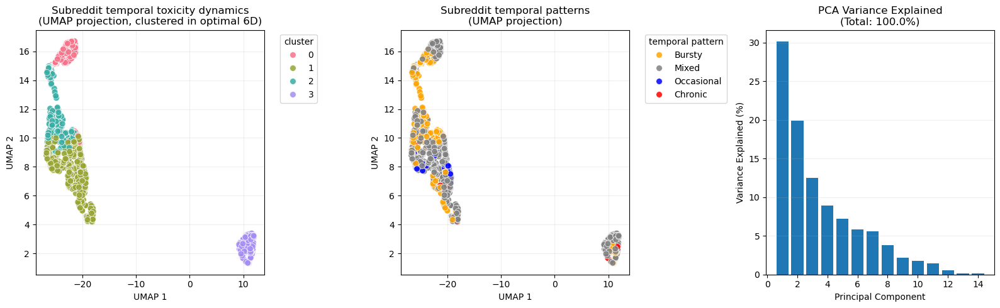

In [37]:
embedding = dimensionality_reduction_2d(X_pca, X_scaled, umap_available, result_df)
plot_cluster_results(result_df, reducer_name, feature_cols, cluster_labels, X_scaled, n_components_optimal)

### Interpretation of Clustering Visualizations

The UMAP projection clearly reveals **four distinct clusters** with good separation, validating our K-Means clustering results. Several key observations emerge from these visualizations:

**Cluster Separation and Quality:**
- The four clusters occupy distinct regions in the 2D space with minimal overlap, indicating that our feature engineering successfully captured meaningful behavioral differences
- Cluster 2 (high-volume balanced hubs) appears more dispersed than other clusters, reflecting the heterogeneity of these highly active communities
- Clusters 0, 1, and 3 show tighter groupings, suggesting more homogeneous behavioral patterns within these groups

**Temporal Pattern Overlay (Middle Panel):**
The temporal pattern distribution aligns **fairly well** with the cluster structure. We observe that:
- **Bursty** communities (orange) concentrate heavily in Cluster 2, confirming that high-volume hubs exhibit coordinated toxic campaigns
- **Mixed** patterns (gray) dominate Clusters 0, 1, and 3, consistent with irregular toxic behavior
- The spatial separation between Bursty and Mixed patterns validates that our temporal features capture distinct behavioral dynamics

However, some **Mixed** subreddits appear within Cluster 2's region (45% of the cluster). This demonstrates that **cluster membership depends on the combination of all features**, not just temporal pattern alone. These Mixed-pattern subreddits are grouped with Bursty ones because they share the defining characteristics of Cluster 2: high activity volume, balanced aggressor-victim roles, and high network connectivity. This confirms our multidimensional approach successfully captures behavioral patterns beyond temporal dynamics alone.

**PCA Variance Explained (Right Panel):**
We include the cumulative variance plot showing that our optimal number of principal components (retaining 80% variance) provides sufficient dimensionality reduction while preserving the essential structure needed for meaningful clustering. The steep initial rise confirms that the first few components capture most of the behavioral variation across subreddits.

In [38]:
create_interactive_plotly_visualization(result_df, reducer_name, feature_cols, n_components_optimal)

### 3.5.3 Mega-Subreddit Analysis



#### Motivation and Validation Approach

Within our clustering results, we identify and analyze **mega-subreddits**,communities with exceptionally high toxic activity volumes that represent extreme cases in the Reddit ecosystem. These subreddits are particularly important for two reasons:

**1. Research Interest**

Mega-subreddits are valuable research cases for us because they:
- Drive a disproportionate amount of toxic interactions across Reddit, making them critical to understanding large-scale toxicity dynamics
- Often represent major community conflicts, polarizing topics, or highly active controversy hubs
- Could be potential intervention targets for platform moderation, given their outsized impact on the toxic network (eventhough this is not the focus of our study)
- May exhibit unique behavioral patterns not captured by typical communities

**2. Clustering Validation (Sanity Check)**

Examining how mega-subreddits are distributed across clusters serves as an important **sanity check** for our clustering quality:
- **If mega-subreddits cluster together**: This suggests the algorithm correctly identifies activity volume as a distinguishing feature, which aligns with our expectation that high-volume communities behave differently
- **If mega-subreddits are distributed across multiple clusters**: This indicates that behavior patterns (temporal dynamics, role balance, network structure) matter beyond just volume, validating that our multidimensional feature engineering captures meaningful distinctions
- **If mega-subreddits within the same cluster show similar roles and patterns**: This confirms that the clustering produces interpretable, coherent behavioral groups even at the extremes of the activity distribution

By analyzing mega-subreddit placement, we can verify that our clustering is **robust to extreme values** and produces **behaviorally meaningful groups** rather than simply separating communities by activity volume alone. This analysis helps ensure that the four identified archetypes represent genuine differences in toxic behavior dynamics.

In [39]:
mega_summary = analyze_mega_subreddits_in_clusters(result_df, n_top=15)


Mega-Subreddit Role Distribution:
mega_role
Mega-Aggressor    13
Mega-Victim       12
Mega-Hub           1
Name: count, dtype: int64
  Mega-Aggressor: 13 (50.0%)
  Mega-Victim: 12 (46.2%)
  Mega-Hub: 1 (3.8%)


#### Results and Implications

**24 out of 26 mega-subreddits concentrate in Cluster 2**, despite exhibiting widely different role orientations. For example strong aggressors like `subredditdrama` and strong victims like `askreddit`. This reveals an important characteristic of our clustering: **temporal dynamics and activity volume dominate over role balance** at extreme activity levels.

While Cluster 2 is characterized by balanced behavior overall (median source=40, target=46), it also takes the mega-subreddits with imbalanced roles because they share the defining **Bursty temporal pattern** and **high network centrality**. This suggests that at very high activity volumes, the *timing and intensity* of toxic interactions matter more than the directional balance.

This check validates that our clustering captures distinct behavioral regimes: for typical communities, role balance is a defining feature (Clusters 0, 1, 3), but for mega-subreddits, the shared characteristic is their capacity for explosive, event-driven toxic activity regardless of whether they primarily send or receive attacks.

## 3.6 Integration into Reddit Map & Communities Detection

Once the clusters of toxic behaviors are computed, we look at their distribution across the Reddit map to observe whether certain topics tend to have a certain behavior, or if agressors and victims are evenly distributed.

In [41]:
# Load and assign toxic behavior clusters from saved csv files to the 2D embeddings
embeddings_with_clusters = assign_clusters_embeddings(embeddings_with_toxicity)

# Plot an interactive map of the embeddings with clusters highlighted
plotly_embeddings(embeddings_with_clusters, highlight="cluster", write=False)

The map shows that although some clusters tend to be more densely distributed in specific areas, each topic contains subreddits of all kinds of toxic behaviors. This result means that we should be able to find interesting cases of toxic interaction networks, with different dynamics, at multiple places on the Reddit map.

### Detecting communities from toxicity behavior 

From the information given by the computed toxic behavior clusters, we isolate networks of toxic interactions illustrating the detected behaviors using the Louvain algorithm, a community detection method that groups nodes in a network into clusters (communities) by maximizing modularity, a measure of how densely connected nodes are within communities compared to between them. 

In our case, we apply the Louvain algorithm to the interactions network, where nodes represent subreddits and weighted edges represent the number of toxic interactions between them. This allows us to identify clusters of subreddits that frequently exchange toxic messages, revealing networks of toxic interactions. By coupling this algorithm to the infomation about the toxic behavior (clusters) of the subreddits involved in the interactions, we can observe the network of interactions to/from subreddits of a specific cluster and save it for further analysis.

In [42]:
# Load and assign toxic behavior clusters from saved csv files to the interactions dataframe (to use in the Louvain algorithm)
interactions_with_clusters=assign_clusters_interactions(interactions_df)

_Example_: we use the Louvain algorithm to find a network in which subreddits from cluster 3 (Low-volume Victim - Mixed) are the target of toxic interactions. To do so, we keep only interactions directed to the cluster of interest before feeding them to the Louvain algorithm and selecting the biggest detected toxic community.

Graph built: 9788 nodes, 26315 toxic edges
Detected 130 communities.
Detected 2 toxic communities.
   COMMUNITY_ID  SIZE
0            38    10
1            63     1
Biggest highly toxic community ID: 38
Number of subreddits in this community: 10


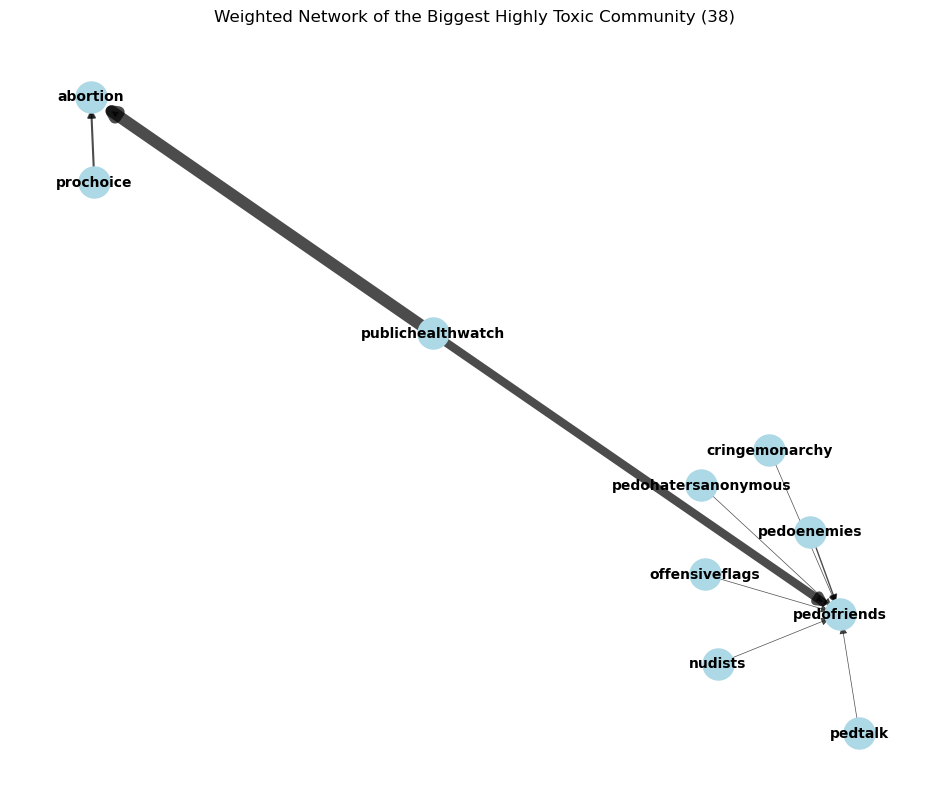

In [43]:
# Only select toxic interactions from/to a cluster of interest to build the graph to detect toxic communities
cluster_of_interest = 3             # 0 to 4
role_of_interest = 'target'         # 'source' or 'target'
cluster_interactions_df = select_cluster_interactions(interactions_with_clusters, cluster=cluster_of_interest, role=role_of_interest)

# Find Louvain communities from toxic interactions by the selected cluster and their number of interactions
community_df, community_interactions = louvain_communities(cluster_interactions_df)

# We consider communities with more than 25% toxic interactions as toxic
toxicity_threshold = 0.25

# Find toxic communities
community_df = get_toxic_communities(community_df, toxicity_threshold)

# Plot the biggest toxic community network
biggest_toxic_community = plot_biggest_toxic_community_network(community_df, community_interactions, write=False)

The graph gives intuitive illustration of the dynamics of toxicity to/from subreddits of a certain cluster. From the output network, we can start a deeper analysis to understand the life cycle of toxicity within this community and the role of subreddits in its propagation. 

---
# Phase 4: Epidemiological Case Studies

We aim to depen our comprehension of the toxic events through case studies. That is, by performing an analysis on a specific time period and for a carefully chosen set of subreddits, we expect to highlight previously-discussed and additional behaviors. 
- First, we select an interesting group of subreddits.
    - A typical subreddit part of a clustered behavior (high-volume balanced (hub) - bursty, low-volume victim - mixt, ...) is chosen and its associated closest neighbors are identified. To this set of neighbors, we add the all subreddits interacting with the initially chosen subreddit. Note that only the union is kept, since some of its neighbors may interact with it. This selected subreddit is called the protagonist.
    
<center><img src="Data/images/1sr_group_selection.png" width="1000"/></center>
<center>Figure: Subreddit Group Selection Schematic.</center>

- Second, we take a reduced time window.
    - From daily interactions over the whole time period (January 2014 to April 2017), we assess peaks and compare them with daily negative interactions over the same period. A period of interest is qualitatively picked.
- Third, we assess if the event is toxic or not.
    - The event is defined as the time series in the selected window of the total negative interactions of all subreddits within the chosen group. Its nature is assessed from the daily activity of the group, and most active subreddits (overall and toxic active) are highlighted. From the trend of negative interactions, we decide if this event is a potential toxic one.
- Finally, we analyze the life cycle of the event.
    - We perform a causal inference analysis using the PCMCI algorithm, reconstructing a causal graph between the most active subreddits time series and the protagonist. This allow us to identify catalysts and true actors in the event, as well as attenuators. Furthermore, death of the event is assigned to passive or active.

*Note that in this section, we will refer as 'global' to indicate a temporal state, meaning over the whole time period available in the original dataset. Comparatively, 'total' will be used to speak about the sum of interactions over subreddits (spatial meaning). This is made to avoid confusion between total interactions and global interactions.*
*Note also that the fourth cluster was not explored as a case-study as it is low-volume, and therefore the associated time series contain less exploitable data.*

In [44]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning, message=".*'H' is deprecated.*")

### 4.1 Time Window Identification

An interesting time window is selected based on the trends of interactions over the whole available time period (global). We argue that the trend of total source and total target interactions adds useful information in addition to a simple global toxic interaction trend. Indeed, this allows us to gather information about the dynamic of the focused group (mostly aggressor or victim interactions).
They add key insights for time window selection, and will be verified later on.

Furthermore, this gives some insights about the associated class, shown in the figure here below.
<center><img src="Data/images/2toxic_event_class.png" width="600"/></center>
<center>Figure: Toxic event classes. a) Single Victim, Multiple Prosecutors b) Multiple Victims, Single Prosecutors c) Multiple Victims, Multiple Prosecutors d) Single Victim, Single Prosecutor.</center>

High source interactions indicate multiple victims, and high target interactions indicate multiple prosecutors. Note that cases where two very active subreddits show both high interactions might be confused for c) or d) equally if no further analysis is done. Catalysts subreddits act indirectly on the event (not necessarily through toxic interactions), and are hard to identify. This is the main reason why neighbor subreddits are selected in addition to interacting subreddits, and we argue that these habitual neighbors are the most likely to act as catalysts. However, such complex interlinked social dynamics cannot be guaranteed to be perfectly modelled this way. As for observational studies where external undetected confounders have underlying effects, we cannot construct a causal analysis encapsulating every confounder with 100% certainty. Moreover, while every scenario may exist, we highlight that most of the toxic events happening in reddit tend to c). Note that prosecutors, victims and catalysts can be labelled as 'participants' for generalization.

Additionally, each interaction (toxic or not) can either have an exciting or attenuating effect, and are not represented in the schematic. They will be assessed in the last part (causal analysis), based on positive or negative correlation of time series.

Here below you will find the results for each Case Study, where the protagonists are: 
- bettersubredditdrame (Cluster 0: moderate-volume aggressors)
- science (Cluster 1: moderate-volume victim leaning)
- drama (Cluster 2: high-volume balanced hub)

Where each section is tackled for each of them in order (time window identification, toxic event assessment, life cycle analysis).

In [46]:
run_time_window_identification(interactions_df, case_study_id=1)

**CS1**: The 'bettersubredditdrama' is particular as it was active only for a short period. However, we can see that the toxic-to-nontoxic ratio of interactions in this period is moderately high, and constant. This makes it a potential chronic toxic subreddit in its lifespan. Furthermore, it almost only interacts as a source, validating its 'aggressor' nature found by clustering. 
We conclude that the time window to consider for this case study is between November 10th 2015 and December 25th 2015.

In [47]:
run_time_window_identification(interactions_df, case_study_id=2)

**CS2**: The 'science' subreddit was subject to numerous bursty events. One of them appears as a dominant toxic event over the whole period and could be interesting to investigate for its rapidly changing behavior. Moreover, most of its interactions over the whole time period are as target, indicating a victim nature (same as clustering prediction). We highlight that the nature of the selected peak between April 15th and May 5th is consistent with this observation, meaning it can also be classified as a victim event.

In [48]:
run_time_window_identification(interactions_df, case_study_id=3)

**CS3**: The 'drama' subreddit is one of the most active on reddit. It has a toxic peak resembling the one of bettersubredditdrama, which makes sense from their thematic closeness. However, its number of interactions is way higher and possesses context before and after, making it non only interesting in itself, but also interesting to compare with the first case study. We can see that the number of source interactions is dominant, indicating an aggressor behavior (consistent with clustering). We therefore select a time window slightly larger than the first case study (i.e. from November 1st 2015 to January 1st 2016) in order to take into account bigger time series data.

### 4.2 Toxic Event Assesment
Now that the time window of interest has been chosen, we can extract from the interaction dataframe only the subreddits in the group (keyword-based ∪ usual neighbors-based), and only the interactions within this time window.
We thus construct the so called focused_df and the associated focused_subreddits.

In [49]:
focused_df1, focused_subreddits1 = run_init_toxic_event_assessment(interactions_df, case_study_id=1)
focused_df2, focused_subreddits2 = run_init_toxic_event_assessment(interactions_df, case_study_id=2)
focused_df3, focused_subreddits3 = run_init_toxic_event_assessment(interactions_df, case_study_id=3)

-------------------------------------------
Case Study 1 :
451 interacting subreddits found.
42 additional neighboring subreddits found. ( 95.45454545454545 % of neighboring subreddits included.)
-------------------------------------------
-------------------------------------------
Case Study 2 :
158 interacting subreddits found.
9 additional neighboring subreddits found. ( 100.0 % of neighboring subreddits included.)
-------------------------------------------
-------------------------------------------
Case Study 3 :
815 interacting subreddits found.
56 additional neighboring subreddits found. ( 91.80327868852459 % of neighboring subreddits included.)
-------------------------------------------


**CS1:** 451 subreddits were found to be interacting with 'drama' over the focused time window. This suggests a toxic event with multi victims (class b or class c based on the toxic event classes). Some of its typical interacting network (habitual neighbors) were indeed interacting with it in this period. Most of them (95%) were not interacting directly, but may be catalysts. That is, they may have effects on its interacting subreddits (analogue to a confounder variable) without having direct connection with it.

**CS2:** For the 'science' subreddit, 158 other subreddits were found to be interacting with it over the chosen time window. From its victim nature, this suggests a multi-agressor scenario (class a or c based on the toxic event classes). None of its habitual neighbors are part of these interacting subreddits, but may still be catalysts. That is, they may have effects on its interacting subreddits (analogue to a confounder variable) without having direct connection with it.

**CS3:** Numerous subreddits (815) are interacting with the 'drama' subreddit. This makes sense as it is a very active subreddit overall. We also note that some habitual neighbors (8%) are part of the interacting subreddits. Because of its high number of source interactions and the high number of interacting subreddits, we assess that this outbreak is linked to a multi-victim scenario (class b or class c based on the toxic event classes). While 92% of its typical interacting network is not directly interacting in this period of time, they may have effects on its interacting subreddits (analogue to a confounder variable) without having direct connection with it.

#### 4.2.1 Total Interactions Over Time
Based on the daily total interactions, we can assess if this event resembles the type previously assigned during clustering:
- Cluster 0: Moderate-volume aggressors,
- Cluster 1: Moderate-volume victim leaning,
- Cluster 2: high-volume balanced hub.

As mentionned previously, this part allows us to discuss if an interaction outbreak indeed appears in the chosen time window. Moreover, the dominance of one type of interaction (source or target) gives information about the class of toxic event it is. In instance, a high source-to-target ratio indicates that most of the focused subreddits interacts towards external subreddits, meaning a typical agressor behavior.

In [50]:
run_daily_interactions(focused_df1, case_study_id=1)

**CS1**: As seen in the global interaction plot, the interactions of 'bettersubredditdrama' are condensed in a short period. We can see more clearly that the total interaction curve overlaps the total source interaction curve, indicating as stated earlier an aggressor behavior. This confirms the clustering belief. Note that a time step of 12h has been set to distinguish more clearly the trends, and to reduce aggregation of data.

In [51]:
run_daily_interactions(focused_df2, case_study_id=2)

**CS2**: In order to identify more precisely the trends and source-to-target interaction ratios, we use a finer time step of 6h in this plot. Data is therefore less aggregated and in addition to the focus on the selected time window, we can assess that the date of concern is around 18:00 on April 23rd 2015. A majority of target interactions shows a victim-type event for the 'science' subreddit, confirming our prior clustering belief. We can also see another interaction outbreak on April 15th 2015, but we need to see the amount of toxic interaction to assess if it is relevant to our study.

In [52]:
run_daily_interactions(focused_df3, case_study_id=3)

**CS3**: From this plot, we can say that the prior belief obtained with clustering is true. A significant amount of source interactions compared to the target ones indeed indicates an aggressor behaviour. Within this focused time window, it is easier to assess that the total number of interactions indeed went up for an extended period (roughly a month). Compared to the first study case, we have a clearer context to compare this outbreak to. Further analysis with the plot of toxic interactions will provide useful information to establish if an extended toxic event indeed took place.

#### 4.2.2 Top Subreddit Interactors
In addition to identifying the class of toxic event and the associated behavior cluster, we take a look at the most active subreddits in this context. This allows us to further classify the event from the number of relevant participants, and perform data reduction to pick the most active subreddits in this case. Typically, the source-to-target interaction ratio is highlighted for each of them, allowing us to identify principal participants. Note that their status as prosecutor, victim or catalyst cannot properly be defined as this is based on their interactions, rather than their toxic interactions (which will be studied in the next parts). Linear axes have been kept because of the stacked bar plots, as a y log-axis would have given more visual importance to very small target interactions compared to those on top of high source interactions. Moreover, the point here is to highlight the differences in activeness, which is easier to assess with a linear axis for dominant subreddits.

In [53]:
sr_interaction_count_df1 = run_top_interactors(focused_df1, case_study_id=1)

**CS1:** From this bar plot, we can conclude that this event is indeed a single prosecutor, multi-victims case (case b). The 'bettersubredditdrama' subreddit is clearly interacting exclusively as a source, meaning the toxic interactions it may have are necessarily as source as well. This is most likely a prosecutor, which is interesting considering its short lifespan. We can hypothesize that it was a highly participating actor in propagating toxicity, and we will verify this hypothesis in the top toxic subreddit interactors section.

In [54]:
sr_interaction_count_df2 = run_top_interactors(focused_df2, case_study_id=2)

**CS2:** As conjectured, the 'science' subreddit is a victim during this event. We can also see that other subreddit have a significant number of interactions, some mostly as target ('askscience'), some as target and source equally ('badsocialscience', 'asksciencefiction'), and some completely as source ('brain_damage'). This indicates we are in a multi-victims, multi-aggressors case (case c). We can highlight that the most active source subreddits are thematically opposed to science, with 'brain_damage', 'badsocialscience', 'conspiracy' and 'badscience' showing up in the top 10 interactors. Furthermore, the 'asksciencefiction' might actually be a false positive, as it has the same keyword in its name but might not interact directly with the 'science' subreddit. We need to see if all these subreddits interact in a toxic manner to confirm these statements.

This comes from how our focusing tool is built, it takes every subreddit with a keyword appear in their name. This ensures no false negatives, but also adds false positives. We argue that this is not an issue as the causal analysis will reveal if it is the case. 

In [55]:
sr_interaction_count_df3 = run_top_interactors(focused_df3, case_study_id=3)

**CS3:** This bar plot confirms our prior belief on the nature of the 'drama' subreddit. Indeed, this subreddit has a high source-to-target interaction ratio, indicating an aggressor nature. What is very interesting is that we can see that the 'drama' subreddit is not the most active in his group. We can conjecture that the subreddit with the most impact is 'subredditdrama', followed closely by 'bettersubredditdrama'. This also links this study case to our first one, showing underlying connections. Since the 'bettersubredditdrama' subreddit has no target interaction, it means the bigger subreddit 'subredditdrama' never targeted it. Moreover, this absence of 'subredditdrama' in the first study case indicates that the bigger subreddits don't actually communicate, but rather focus on multiple, smaller victims. This is key in defining the type of toxic event, and suggests that these subreddits are allied against smaller victims.

Note that from how our focusing tool is built, every subreddit with a keyword appearing in their name is selected. This ensures no false negatives, but also adds false positives. We argue that this is not an issue as the causal analysis will reveal if it is the case.

#### 4.2.3 Toxic Interactions over Time
Further analysis of toxic interactions is performed in this subsection. The evolution of the total toxic interactions is key in indicating if the interaction outbreak is indeed toxic. Additionally, a moving average is shown to confirm a change in trend. The toxicity nature of an interaction is decided based on their categorical feature presented earlier:
- 'TOXICITY_CAT' == 1

As a reference, we give here below the typical toxic traits over the whole dataframe (not focused).

In [56]:
average_toxicity_traits(interactions_df)

Average daily toxicity: 0.075
Average toxic duration: 161.96 hours


The average toxic duration is the average time separating an interaction labelled as TOXICITY_CAT == 1 and another one labelled as TOXICITY_CAT == 0 for the same subreddit. Even if it is a bit less than a week, one toxic interaction per day for a week should not be considered a toxic event. We define that a significant outbreak of toxicity >> average daily toxicity is a bursty toxic event, and that high daily toxicity levels for a longer period than a week is considered a long-term toxic event.

In [57]:
daily_neg_interaction_df1 = run_toxic_interactions_over_time(focused_df1, case_study_id=1)

**CS1:** It is clear from this plot that the amount of toxic interaction is non-negligible over the selected period. Even if we don't have much context in such a short lifespan, it can be argued that the whole period of existence of this subreddit is equally toxic, and sufficiently toxic to be considered a chronic toxic subreddit. We emphasize that a typical subreddit has globally close to no toxic interaction, while the moving average here is fluctuating around 4 toxic interactions per day. We conclude this is a toxic event, with 'bettersubredditdrama' as the protagonist. Its role in the event will be identified in the next sections.

In [58]:
daily_neg_interaction_df2 = run_toxic_interactions_over_time(focused_df2, case_study_id=2)

**CS2:** From the moving average, we can assess that this is a bursty toxic event. The rest of the context (toxic interactions around the peak) shows that this subreddit is usually not involved in toxic events. We can also say that the previous outbreak seen in the total interaction plot was not a toxic outbreak, but simply an interaction outbreak.

In [59]:
daily_neg_interaction_df3 = run_toxic_interactions_over_time(focused_df3, case_study_id=3)

**CS3:** As for the first study case, this event can be classified a long-term toxic event. The trend given by the 3-day average shows an overall increase in the number of toxic interactions over the course of a month, which is long enough to be considered long-term. Since this subreddit is already on average more toxic than the average, this even more toxic period is considered as a long-term toxic event.

#### 4.2.4 Top Toxic Subreddit Interactors
Finally, we add a plot showing the number of toxic interactions for each subreddit. This allow us to identify the most toxic subreddits, and therefore more precisely select the most active participants in terms of toxicity later on. We use here a log scale for the y-axis as we don't have stacked plots, and to improve readability.

In [60]:
run_top_toxic_interactors(focused_df1, case_study_id=1)

**CS1:** As for the top interactors, the 'bettersubredditdrama' subreddit appears as the dominant toxic interactor. This confirms our conjecture about its role as the principal aggressor in its group. The number of toxic interactions, combined with its interactions being mostly as source, makes it a typical hyper aggressor towards multiple victims.

In [61]:
run_top_toxic_interactors(focused_df2, case_study_id=2)

**CS2:** We can see that the 'science' subreddit is still in the top 3 of most toxic interacting subreddits. However, we highlight that the first and second subreddits were not that high in the total interaction bar plot. The previously identified antithetic subreddits do not turn out to be the most toxic in the 'science' group. Nevertheless, their non-toxic interactions could turn out to have an effect on the toxic interactions of the 'science' subreddit, as catalysts would do. Additionally, the number of toxic interactions is very low (5) compared to the number of total interactions (80). This is still a toxic event for the subreddit in itself, but on a different scale. We highlight that this kind of bursty toxic event is common for small subreddits, especially because the average daily toxicity indicates less than 1 out of 10 toxic interactions. Even an outbreak of 5 toxic interactions is relevant in our study, and provides useful data on the different scales of such events.

In [62]:
run_top_toxic_interactors(focused_df3, case_study_id=3)

**CS3:** As in the bar plot of top interactors, 'subredditdrama', 'bettersubredditdrama' and 'drama' dominate as the most active toxic interactors. This further entails their role as major aggressors. We can say they probably form the aforementioned alliance as prosecutors, propagating toxicity to numerous victims without interacting with one another.

### 4.3 Life Cycle Analysis
From the previously gathered information, we are now able to select the most active participants, in terms of interactions and toxic interactions. We aim to confirm our beliefs on prosecutors and catalysts, and identify potential attenuators based on the causal inferences on the protagonist subreddit. Using a state-of-the-art algorithm for causal inference on time series, namely PCMCI (Peter and Clark Momentary Conditional Independence) algorithm [3], we can assess the effect of the most active subreddits on the protagonist. 

See below an overview of its working principle. 
PCMCI: Distinguish causal relationships (based on time series data, from spurious correlations) by taking into account autocorrelation and confounding variables.
1) PC Phase
    - Uses a simplified PC algorithm to identify a set of potential parents for each variable
    - For each variable, tests conditional independence with lagged versions of all variables
    - Iteratively removes spurious links by conditioning on increasingly larger sets of past variables
    - Output: A preliminary causal graph with candidate parent sets for each variable

2. MCI Phase
    - Refines the results from the PC phase
    - For each remaining link, performs a more rigorous conditional independence test
    - Conditions on the parents identified in the PC phase to determine if the link is truly causal
    - Tests independence at specific time lags
    - Output: Final causal graph with strength and significance of causal links

<center><img src="Data/images/3PCMCI_algo.png" width="600"/></center>
<center>Figure: PCMCI steps. Red nodes: conditioning set for X³_t; Blue nodes: conditioning set for X¹_t; Star: False Positives. (Adapted from [1])</center>

Different conditional independence tests can be used, including partial correlation (linear gaussian), rank-based/robust partial correlation, GPDC (nonlinear dependence via Gaussian processes), CMIknn (General conditional), Regression Conditional Independence (residual independence after regression) and Partial Correlation with Weighted Least Square. In our case, the robust partial correlation makes more sense, as it is usually used for social interaction data. Note however that it may miss nonlinear dependencies.

Red links are positively correlated and green links are negatively correlated. Colored links are only drawn towards or from the protagonist. Lag is also shown, and indicates the time taken from one time series to affect the pointed node. As mentioned in the early phase of this section, such social links form a complex web of interlinked connections. PCMCI allows us to determine statistical dependence and correlation between time series, but is not a magical tool. The obtained causal graph is a representation of the causal interactions through statistical relevance, based on our assumptions. For example, we only analyze the most active subreddits, while the real connections might be the result of hundreds of low interacting subreddits. Unmodelled confounders indeed have an effect that cannot be seen in this graph, giving a simplified final analysis. This is also why only the protagonist is analyzed, since it reduces the number of links to take into account. We highlight that the graphs we obtain make sense as the effect on one subreddit is never considered from a single source.

The tigramite library is used to perform PCMCI on our time series data (see [2]).

[1]: Causal Discovery with Multivariate Time Series Data (https://medium.com/causality-in-data-science/causal-discovery-with-multivariate-time-series-data-a3f7ffc16747)

[2]: Tigramite Documentation (https://jakobrunge.github.io/tigramite/index.html#)

[3]: Krich, C., Runge, J., Miralles, D. G., Migliavacca, M., Perez-Priego, O., El-Madany, T., ... & Mahecha, M. D. (2020). Estimating causal networks in biosphere–atmosphere interaction with the PCMCI approach. Biogeosciences, 17(4), 1033-1061.

We construct 2 causal graphs: 
- one to assess causality between the toxic interaction time series of the protagonist and the non-toxic interaction time series of relevant subreddits,
- the other to assess causality between the toxic interaction time series of the protagonist and the toxic interaction time series of relevant subreddits.
They give information about how other subreddits cause toxic interactions in the protagonist time series, from their non-toxic interactions (i.e. as catalysts) and from their toxic interactions (i.e. as prosecutors).

In [63]:
edges1, edges_neg1, finer_focused_subreddits1 = run_pcmci_analysis(daily_neg_interaction_df1, focused_subreddits1, sr_interaction_count_df1, interactions_df, case_study_id=1)
plot_pcmci_interactive_html(edges1, finer_focused_subreddits1, case_study_id_py=0, output_html=f"Data/Results_html/CS1/CS1_7_PCMCI.html")
plot_pcmci_interactive_html(edges_neg1, finer_focused_subreddits1, case_study_id_py=0, identifier='(Toxic on Toxic)', output_html=f"Data/Results_html/CS1/CS1_8_PCMCI_negative.html")

**CS1:** From these causal graphs, we can identify subreddits having a direct effect on the protagonist. The entire graph shows a complex web of causality, which is expected since we work with complex social data.

A very interesting finding lies in the effect of non-toxic interactions from subreddits that have a direct impact on the protagonist’s toxic interactions. Among others, 'conspiracy' and 'anarchism' exhibit a positive correlation in this sense, meaning they act as catalysts. On the other hand, 'adviceanimals' appears to have an attenuating effect on the toxic trend at first (1-day lag).

The protagonist itself also has an effect on others, meaning that other subreddits may follow its trend due to its influence. This is the case for 'adviceanimals', which is positively correlated with the protagonist after some time (3-day lag). This highlights an interesting dynamic, where the effect of one subreddit on another is not symmetric in the opposite direction.

Furthermore, the protagonist’s trend is negatively correlated with the trends of non-toxic interactions in 'pics' and 'relationships', indicating that the number of non-toxic interactions drops when the number of toxic interactions of the protagonist increases. No calming links were highlighted here (i.e., non-toxic time series negatively correlated with the toxic time series of the protagonist), which suggests a passive decay of the toxic event.

The second causal graph confirms the aggressor behavior of the protagonist. Indeed, its positively correlated directed links towards 'conspiracy', 'pics', and 'hiphopheads' indicate a propagation of its own toxic trend. It also appears to be influenced by other subreddits, such as 'drama', 'worldnews', and 'relationships'. An especially interesting causal link is observed with 'anarchism', which shows a strong negative correlation towards the protagonist. This suggests that toxic interactions within 'anarchism' lead to a significant drop in the number of toxic interactions of the protagonist after approximately 2.5 days. This could indicate that 'anarchism' acts as a toxic attenuator, calming the trend through toxic interactions.

In [64]:
edges2, edges_neg2, finer_focused_subreddits2 = run_pcmci_analysis(daily_neg_interaction_df2, focused_subreddits2, sr_interaction_count_df2, interactions_df, case_study_id=2)
plot_pcmci_interactive_html(edges2, finer_focused_subreddits2, case_study_id_py=1, output_html=f"Data/Results_html/CS2/CS2_7_PCMCI.html")
plot_pcmci_interactive_html(edges_neg2, finer_focused_subreddits2, case_study_id_py=1, identifier='(Toxic on Toxic)', output_html=f"Data/Results_html/CS2/CS2_8_PCMCI_negative.html")

/opt/miniconda3/envs/ada/lib/python3.13/site-packages/tigramite/independence_tests/robust_parcorr.py:402: RuntimeWarning:

divide by zero encountered in log

/opt/miniconda3/envs/ada/lib/python3.13/site-packages/tigramite/independence_tests/robust_parcorr.py:221: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



**CS2:** From these causal graphs, we can identify subreddits having a direct effect on the protagonist. The entire graph shows a complex web of causality, which is expected since we work with complex social data.

The first graph reveals an intricate interaction between the protagonist ('science') and four other subreddits. Notably, 'everythingscience' was previously identified as an additional victim alongside 'science', while 'badsocialscience' was identified primarily as an aggressor, although it also received some toxic interactions. Here, we observe that the number of toxic interactions of 'science' is highly correlated with non-toxic interactions of 'everythingscience' and 'badscience', suggesting that toxic interactions of 'science' propagate to others via non-toxic interactions with a small lag (12 hours).

The strong negative correlation with 'conspiracy' indicates that a toxic event affecting 'science' leads to a corresponding decrease in the number of non-toxic interactions of 'conspiracy'. Finally, the 'badsocialscience' subreddit shows a highly correlated link towards the toxic interactions of the protagonist, indicating that its non-toxic interactions are likely to trigger a toxic event involving the protagonist. We can therefore assess that 'science' is indeed part of a victim group, and that 'badsocialscience' contributed to this toxic outbreak. No calming links were identified here, suggesting once again a passive decay of the toxic event.

The second graph provides additional insight. In particular, the 'badscience' subreddit emerges as one of the most likely patient-zero candidates. Its low-lag, highly correlated link towards the protagonist suggests strongly coupled dynamics and thus a significant influence. We can also highlight the important influence of the protagonist on 'badsocialscience' and 'conspiracy', as previously mentioned.

A particularly interesting dynamic appears in the time-varying nature of the 'science' → 'badsocialscience' link: it is strongly positively correlated at low lags (6 hours) and strongly negatively correlated at higher lags (24 hours). Lastly, we observe that 'conspiracy' is positively correlated, indicating that not only do non-toxic interactions decrease when the protagonist’s toxic interactions increase, but its toxic interactions increase as well. We can therefore conclude that 'conspiracy' plays the role of a prosecutor, as suggested in the top-subreddit-interactors analysis.

Note that 'brain_damage' was identified as a false positive, as it exhibits no causal links with any other subreddit, neither through non-toxic nor toxic interactions.


In [65]:
edges3, edges_neg3, finer_focused_subreddits3 = run_pcmci_analysis(daily_neg_interaction_df3, focused_subreddits3, sr_interaction_count_df3, interactions_df, case_study_id=3)
plot_pcmci_interactive_html(edges3, finer_focused_subreddits3, case_study_id_py=2, output_html=f"Data/Results_html/CS3/CS3_7_PCMCI.html")
plot_pcmci_interactive_html(edges_neg3, finer_focused_subreddits3, case_study_id_py=2, identifier='(Toxic on Toxic)', output_html=f"Data/Results_html/CS3/CS3_8_PCMCI_negative.html")

**CS3:** From these causal graphs, we can identify subreddits having a direct effect on the protagonist. The entire graph shows a complex web of causality, which is expected since we work with complex social data.

The first graph reveals an intricate set of interactions between the protagonist ('drama') and several other subreddits. Since we previously identified this subreddit as an aggressor allied with 'subredditdrama' and 'bettersubredditdrama', we focus primarily on these links. We observe that 'drama' is influenced by several catalysts. In particular, the number of non-toxic interactions of 'anarchism' is positively correlated with its toxic interactions, suggesting that 'anarchism' may act as a patient-zero.

We can also observe the effect of the protagonist on others. Notably, 'subredditdrama' and 'bettersubredditdrama' show a decrease in the number of non-toxic interactions when 'drama' exhibits increasing toxic interactions, suggesting a coupled dynamic among allied subreddits, as previously conjectured.

The second graph highlights a tight relationship between the main drama-related subreddits, including 'subredditdrama', 'mildredditdrama', and 'drama'. This confirms our hypothesis regarding their alliance-type dynamics. The role of the protagonist as an aggressor is further supported by its direct influence on the toxic interaction time series of 'relationships', which was identified as one of several victims.

Finally, we observe the presence of a negative autocorrelation link, indicating a self-calming behavior of the protagonist. This suggests that the toxic event ended through a low-activity decay.

No false positives were identified in this case.


### 4.4 Case Study Conclusions

**CS1:** To put it in a nutshell, we managed to confirm the aggressor behavior of the 'betterdramasubreddit' subreddit through a specific, in-depth case study. Its relatively low lifespan revealed the existence of an all-time toxic subject that strongly impacts other communities. We identified the nature of the toxic event as a long-term toxic outbreak, and clearly highlighted its victims as well as its most active interaction network.

We completed our study by providing insights into the propagation agents, removing false positives, identifying potential patient-zero candidates, and characterizing the death type of the event (passive, natural). Through this work, we gathered valuable information that helps us better understand the toxicity phenomenon and confirms our conjecture regarding the existence of distinct toxicity variants.

This case study also emphasizes the presence of complex and highly interconnected networks, for which the most reasonable response to such outbreaks would be moderation of interactions rather than isolated interventions. Actions ranging from simple verification of interaction toxicity to quarantine-like mechanisms are therefore strongly supported.

**CS2:** To put it in a nutshell, we managed to confirm the victim behavior of the 'science' subreddit through a specific, in-depth example. The highly bursty nature of its toxic event demonstrated that such a phenomenon exists and follows dynamics distinct from long-term outbreaks. We identified this event as a bursty toxic event and highlighted its prosecutors, as well as the most relevant interaction network involved in the outbreak.

We completed our study by providing insights into the propagation agents, again removing false positives, identifying potential patient-zero candidates, and determining the death type of the event (passive, natural). These findings further contribute to our understanding of toxicity dynamics and reinforce our hypothesis regarding multiple variants of toxic behavior.

As in CS1, this case underscores the existence of intricate interaction networks, suggesting that effective mitigation strategies should focus on moderating inter-community interactions. Measures such as toxicity-aware filtering or quarantine-like controls appear well justified in this context.

**CS3:** To put it in a nutshell, we managed to confirm the aggressor behavior of the 'drama' subreddit through a specific, in-depth case study. We demonstrated the existence of allied aggressor communities, and highlighted their tight dynamics extending beyond purely toxic interactions. We identified this event as a long-term toxic outbreak, and mapped its victims, its most active interaction network, and its allied subreddits.

We completed our study by providing insights into the propagation agents, removing false positives, identifying potential patient-zero candidates, and characterizing the death type of the outbreak as low-active and mostly natural. These results further validate our conjecture regarding toxicity variants and emphasize the role of coordinated dynamics between communities.

Once again, this case illustrates the complexity of Reddit’s interaction networks. As with the previous studies, our findings strongly support the idea that moderation of interactions—rather than isolated content removal—would be the most effective strategy to mitigate such toxic outbreaks.

---
# Phase 5: Synthesis and Conclusion 

In conclusion, our team was able to identify the different variants of toxicity circulating in the Reddit archipelago and how these variants manifest across different types of communities. In addition, we highlighted influence between individual communities and causal pathways in the spread of toxic behavior. 

After building a new metric that allows to classify types of toxicity propagation, we observed their distribution on a thematic mapping of subreddits. In depth analysis of three specific study cases helped us confirm our prior beliefs on toxicity variants, propagation mechanics and network interactions.

The task we have decided to tackle is complex, and we are aware that further studies are still needed to consolidate the understanding of such events. Social interactions are inherently full of underlying effects and causes, and care should be taken when trying to find generalized answers.